# Exploratory data analysis of the mouse database

Background for the *Data* section of the paper. The notebook describes the whole database briefly
(Part A), the experiment behind the study cohort in more detail (Part B, trail 3) and the study
cohort itself in depth (Part C): the 186 mice and 3,049 daily weights that the results in
`mouse_with_context.ipynb` are computed on. Part D collects the key numbers in one table.

The cohort is loaded with exactly the loader and configuration of the results notebook
(`michael.load_dataset`, trail 3, roles RT/RChT/ChT), so every number here matches the results.
The database is in German; all labels are translated in the setup cells below. Nothing is written
to disk.

## 0. Setup

In [1]:
import logging
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from statsmodels.duration.survfunc import SurvfuncRight

from tfmplayground.mouse import michael, preprocessing
from tfmplayground.mouse.preprocessing import THERAPY_TYPES, PreprocessingConfig, build_info_df
from tfmplayground.mouse.rolling import MIN_CONTEXT, rolling_metrics, rolling_origins, rolling_predictions

logging.basicConfig(level=logging.INFO, format="%(message)s")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

In [2]:
# Same data and configuration as mouse_with_context.ipynb
DATAPATH = preprocessing.RAW_PICKLE_PATH  # "/data/mice/maus.pandas.pkl"
load_dataset = michael.load_dataset
config = PreprocessingConfig(
    trails=[3],
    roles=[1, 2, 3],
    min_length=5,
    max_weight=100,
    num_animals=4000,
    num_test_animals=4000,
    prediction_length=1,
    seed=None,
)
TRAIL = config.trails[0]
COHORT_ROLES = config.roles
# Cached rolling forecasts of the results notebook, only used to cross-check the number of forecast origins
ROLLING_CACHE = "/data/PFN/Mouse/rolling/tabpfn_trail3.parquet"

### Translations of the German lookup tables
Role (`Rollen`), cause of death (`Todesursachen`) and killing method (`Toetungsarten`) are translated
from the lookup tables; the trail names and aims from `Versuchsreihen`, the project titles from
`Tierversuche`.

In [3]:
# Rollen: role = treatment group of a mouse. Role 0 is used in Versuchstiere but missing in Rollen.
ROLE_ABBR = {0: "–", 1: "RT", 2: "RChT", 3: "ChT", 4: "K", 5: "E", 6: "V", 7: "B", 8: "KT", 9: "OP", 10: "Abort", 11: "NNZ"}
ROLE_NAMES = {
    0: "Unassigned (role 0, not in lookup)",
    1: "RT: radiotherapy",
    2: "RChT: radiochemotherapy",
    3: "ChT: chemotherapy",
    4: "K: control animal at the start",
    5: "E: control animal at the end",
    6: "V: pilot experiment",
    7: "B: observation without therapy",
    8: "KT: no local tumour despite injection, or early termination",
    9: "OP: surgical removal of the primary tumour",
    10: "Abort: termination for general condition / spontaneous death",
    11: "NNZ: not yet assigned",
}
DEATH_CAUSES = {
    1: "Unknown",
    2: "Experiment ended as planned",
    3: "Killed: tumour ulceration",
    4: "Killed: poor general condition",
    5: "Spontaneous death",
    6: "Unknown: disposed of by animal care",
    7: "Poor general condition / suspected lymphoma",
    8: "Death directly after surgery",
}
KILL_METHODS = {
    1: "CO2",
    2: "Cervical dislocation",
    3: "Spontaneous death (not killed)",
    4: "Final blood sampling",
    5: "Final ketamine anaesthesia",
}
ROUTES = {1: "unknown", 2: "i.p.", 3: "i.a.", 4: "i.v.", 5: "s.c.", 6: "oral gavage"}
SITES = {
    1: "s.c., right flank (injection)",
    2: "s.c., right side, end of thorax (injection)",
    3: "primary tumour",
    4: "lung (necropsy)",
    5: "liver (necropsy)",
    6: "bone marrow right femur (necropsy)",
    7: "bone marrow right tibia (necropsy)",
    8: "bone marrow femur + tibia (necropsy)",
    9: "cerebrum (necropsy)",
    10: "intestine (necropsy)",
    11: "muscle",
    12: "kidneys (necropsy)",
    13: "s.c., subscapular (injection)",
    14: "stereotactic brain injection",
    15: "spleen (necropsy)",
}
# Injection sites and the primary tumour; the other sites are organs examined at necropsy
PRIMARY_SITES = [1, 2, 3, 13, 14]
TUMOUR_TYPES = {
    "OH-1 RGB": "small-cell lung cancer (SCLC)",
    "H69 RGB": "small-cell lung cancer (SCLC)",
    "LNCaP RGB": "prostate cancer (androgen-sensitive)",
    "PC-3 RGB": "prostate cancer (androgen-independent)",
    "VCaP RGB": "prostate cancer",
    "PC-3": "prostate cancer (androgen-independent)",
    "PC-3 RGB + Luziferase": "prostate cancer (androgen-independent)",
    "HT29": "colorectal cancer",
    "HCT116": "colorectal cancer",
    "CACO-2": "colorectal cancer",
    "SW48": "colorectal cancer",
    "PymT": "murine breast cancer (MMTV-PyMT)",
    "MCF7": "breast cancer",
    "OH1": "small-cell lung cancer (SCLC)",
    "H69AR RGB": "small-cell lung cancer (SCLC)",
    "H69AR Luziferase": "small-cell lung cancer (SCLC)",
    "GL261": "murine glioblastoma",
    "NCH644OBC": "glioblastoma",
}
TRAIL_NAMES = {
    1: ("Pilot 1", "dose finding; tolerability; tumour growth"),
    2: ("Cell migration under irradiation", "migration of in-vivo labelled cells into an irradiated area"),
    3: ("Main experiment 1", "effect of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on "
        "metastasis in xenograft mouse models; clonal selection of metastases"),
    4: ("Pilot Loges 1", "resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer"),
    5: ("Pilot 1 (methods)", "learning methods; animal handling; tumour growth"),
    6: ("Breast cancer model", "tumour-specific radiosensitisation by targeted inhibition of DNA repair"),
    7: ("Nanoparticles", "MRI of tumours; changes due to nanoparticles; changes due to local radiotherapy"),
    8: ("Pilot 1 cell migration", "migration of tumour cells; response to radiotherapy in the luciferase signal"),
    9: ("Pilot 1 olaparib", "effect of olaparib; test of cells and tissues; radiation response of normal tissue"),
    10: ("Main experiment TAS102", "efficacy of TAS102; tolerability; tumour growth"),
    11: ("Pilot PC3", "dose finding; tolerability; tumour growth"),
    12: ("Main experiment PC3", "effect of radiotherapy, chemotherapy, radiochemotherapy and surgery on metastasis; "
         "clonal selection of metastases"),
    13: ("Pilot N006/2020", "dose finding; tolerability; method test"),
    14: ("Main experiment N006/2020", "immunomodulation in glioblastoma"),
    15: ("Main experiment N052/2020", "response of metastases; response of brain tumours"),
}
PROJECT_TITLES = {
    1: "Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in "
       "xenograft mouse models",
    2: "Selectin-dependent interaction of cell populations in a clinically relevant human tumour model under therapy",
    3: "Resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer",
    4: "Role of the TAM receptor family in myeloid leukaemias",
    5: "Pilot with two animals: learning methods",
    6: "Tumour-specific radiosensitisation by targeted inhibition of DNA repair",
    7: "Radiosensitisation of PTEN- or CHD1-depleted prostate carcinomas by PARP1 inhibition",
    8: "TAS102",
    9: "Selectin-dependent interaction of cell populations in a human tumour model under therapy (cell migration)",
    10: "Influence of locally ablative radiotherapy, chemotherapy, radiochemotherapy and surgery on metastasis in two "
        "xenograft mouse prostate models",
    11: "Immunomodulation by radiotherapy in glioblastoma",
    12: "Relevance of clonal heterogeneity for cerebral tropism and radiotherapy response of brain tumours",
}
# Category and content of every table in the pickle
TABLE_INFO = {
    "Versuchstiere": ("core", "one row per mouse: trail, role (treatment group), sex, strain, birth and death date, "
                              "cause of death, killing method, RT/ChT protocol, injection batch"),
    "Visiten": ("core", "one row per visit: body weight, relative weight, burden score sheet (weight, general "
                        "condition, behaviour, tumour), tumour volume"),
    "Bestrahlungen": ("treatment", "one row per radiotherapy fraction: planned/delivered dose, field, date, time"),
    "Chemotherapie": ("treatment", "one row per chemotherapy administration: drug, protocol, dose, route, date"),
    "Operationen": ("treatment", "surgeries (removal of the primary tumour), with tumour weight"),
    "Narkosen": ("treatment", "anaesthesia sessions (agent, gas flows, date)"),
    "Tumor": ("outcome", "tumours per mouse: site, cell line, injection date, removal date, tumour weight"),
    "Tierversuche": ("design", "approved animal-experiment projects with licence number"),
    "Versuchsreihen": ("design", "trails (experiment series): name, aims, start/end date, project"),
    "Kohorten": ("design", "cohorts: trail × cell line × mouse strain"),
    "VGruppe": ("design", "injection batches: cohort, cell line, date"),
    "Rollen": ("lookup", "roles = treatment groups (RT, RChT, ChT, controls, ...)"),
    "Todesursachen": ("lookup", "causes of death"),
    "Toetungsarten": ("lookup", "killing methods"),
    "Tiertypen": ("lookup", "mouse strains (and human as source of the tumour cells)"),
    "Tumorzelllinien": ("lookup", "tumour cell lines"),
    "Topographie": ("lookup", "anatomical sites (injection sites, organs at necropsy)"),
    "SeitenBez": ("lookup", "body side"),
    "RTKonzepte": ("lookup", "radiotherapy protocols: dose per fraction, total dose, fractions per day/week"),
    "ChTKonzepte": ("lookup", "chemotherapy protocols: up to three drugs with dose, route and days"),
    "ChemoMed": ("lookup", "chemotherapy drugs"),
    "Applikation": ("lookup", "administration routes"),
    "Zuechter": ("lookup", "breeders / suppliers of the mice"),
    "Prozeduren": ("notes", "free-text clinical procedures (fluids, soft food, isolation, ...)"),
    "Tagescheck": ("admin", "daily quality check of the irradiation device"),
}
CATEGORY_ORDER = ["core", "treatment", "outcome", "design", "lookup", "notes", "admin"]

### Plot style and helpers
Therapy groups keep one colour throughout the notebook (RT blue, RChT orange, ChT aqua); cell lines
use three other hues so that they are never confused with the therapy groups.

In [4]:
INK, MUTED, GRID = "#222222", "#8a8a8a", "#e6e6e3"
THERAPY_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
THERAPY_ABBR = {role: ROLE_ABBR[role] for role in COHORT_ROLES}
CELL_COLORS = {"OH-1 RGB": "#e87ba4", "H69 RGB": "#008300", "LNCaP RGB": "#6250d6"}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
})


def median_iqr(x, digits=0, unit=""):
    """'median [Q1–Q3]' of the non-missing values."""
    x = pd.Series(x, dtype=float).dropna()
    if x.empty:
        return "–"
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    return f"{med:.{digits}f} [{q1:.{digits}f}–{q3:.{digits}f}]{unit}"


def n_pct(count, total):
    """'n (p%)'."""
    return f"{count} ({100 * count / total:.0f}%)" if total else "0"


def named_crosstab(index, columns, margins=True):
    """Crosstab with a 'Total' row and column."""
    return pd.crosstab(index, columns, margins=margins, margins_name="Total")


FACTS = {}


def fact(name, value):
    """Remember a number for the summary in Part D and return it."""
    FACTS[name] = value
    return value

### Load the raw tables and the study cohort

In [5]:
tables = pd.read_pickle(DATAPATH)
# The study cohort, exactly as in the results notebook
df = load_dataset(DATAPATH, config)
info_df = build_info_df(df)
print(f"{len(tables)} tables; cohort: {df['item_id'].nunique()} mice, {len(df)} rows")
df.head()

Animals: 188 -> 186 after filtering -> 186 sampled


25 tables; cohort: 186 mice, 3049 rows


,item_id,timestamp,time,target,radio,chemo,intervention,trail,role
0,3,2013-08-05,13:00:00,32.5,0,0,0,3,1
1,3,2013-08-09,13:00:00,28.9,0,0,0,3,1
2,3,2013-08-13,13:30:00,29.0,0,0,0,3,1
3,3,2013-08-14,08:00:00,29.5,0,0,0,3,1
4,3,2013-08-19,08:39:00,29.4,0,0,0,3,1


### Tidy English versions of the core tables
`mice` (one row per animal), `visits` (one row per visit) and one frame per treatment. These are only
used for the description; the cohort `df` above comes straight from the loader.

In [6]:
def lookup(table, key, value):
    return tables[table].set_index(key)[value]


vt = tables["Versuchstiere"]
batches = tables["VGruppe"].set_index("IdVGruppe")
mice = pd.DataFrame({
    "id": vt["IdTier"],
    "trail": vt["Versuchsreihe"],
    "role": vt["Rolle"],
    "role_abbr": vt["Rolle"].map(ROLE_ABBR),
    "sex": vt["Geschlecht"].map({"m": "male", "w": "female"}),
    "strain": vt["IdTiertyp"].map(lookup("Tiertypen", "IdTiertyp", "Tiertyp")),
    "batch": vt["VGruppe"],
    "cohort": vt["VGruppe"].map(batches["Kohorte"].map(lookup("Kohorten", "IdKohorte", "KohorteName"))),
    "cell_line": vt["VGruppe"].map(batches["Zelllinie"].map(lookup("Tumorzelllinien", "IdZelllinie", "NameZelllinie"))),
    "birth": pd.to_datetime(vt["Geburtsdatum"], errors="coerce"),
    "death": pd.to_datetime(vt["Sterbedatum"], errors="coerce"),
    "death_cause": vt["Todesursache"].map(DEATH_CAUSES),
    "kill_method": vt["Toetungsart"].map(KILL_METHODS),
    "rt_concept": vt["RTKonzept"],
    "cht_concept": vt["ChTKonzept"],
    "note": vt["Bemerkung"],
})

tumours = tables["Tumor"].assign(
    injection=lambda x: pd.to_datetime(x["TransDatum"], errors="coerce"),
    removal=lambda x: pd.to_datetime(x["EntnahmeDatum"], errors="coerce"),
    site=lambda x: x["IdTopographie"].map(SITES),
)
primary = tumours[tumours["IdTopographie"].isin(PRIMARY_SITES)]
mice["injection"] = mice["id"].map(primary.groupby("IdTier")["injection"].min())
mice["tumours"] = mice["id"].map(primary.groupby("IdTier").size()).fillna(0).astype(int)
mice["tumour_weight"] = mice["id"].map(primary.groupby("IdTier")["TuGewicht"].sum(min_count=1))

vis = tables["Visiten"]
visits = pd.DataFrame({
    "id": vis["IdTier"],
    "date": pd.to_datetime(vis["Visitendatum"], errors="coerce"),
    "time": vis["Visitenzeit"],
    "weight": vis["Gewicht"],
    "rel_weight": pd.to_numeric(vis["KGVerlauf"], errors="coerce"),
    "kg_points": vis["KGPunkte"],
    "az_points": vis["AZPunkte"],
    "vh_points": vis["VHPunkte"],
    "tu_points": vis["TUPunkte"],
    "score": vis["Score"],
    "tumour_volume": vis["TUVolumen"],
    "ulceration": vis["TUExulceration"],
    "raw_date": vis["Visitendatum"],
}).merge(mice[["id", "trail", "role"]], on="id", how="left")

radio = tables["Bestrahlungen"].assign(
    id=lambda x: x["IdTier"],
    date=lambda x: pd.to_datetime(x["Datum"], errors="coerce"),
    concept=lambda x: x["IdRTKonzept"].map(lookup("RTKonzepte", "IdRTKonzept", "RTKonzept")),
)
chemo = tables["Chemotherapie"].assign(
    id=lambda x: x["IdTier"],
    date=lambda x: pd.to_datetime(x["ChTDatum"], errors="coerce"),
    drug=lambda x: x["IdChTMed"].map(lookup("ChemoMed", "IdChemoMed", "NameMed")),
    concept=lambda x: x["IdChTKonzept"].map(lookup("ChTKonzepte", "IdChTKonzept", "NameChTKonzept")),
    route=lambda x: x["IdApplikationIst"].map(ROUTES),
)
surgery = tables["Operationen"].assign(id=lambda x: x["IdTier"], date=lambda x: pd.to_datetime(x["DatumOP"], errors="coerce"))
anaesthesia = tables["Narkosen"].assign(
    id=lambda x: x["IdTier"], date=lambda x: pd.to_datetime(x["NarkoseDatum"], errors="coerce")
)
trail_of = mice.set_index("id")["trail"]
for frame in (radio, chemo, surgery, anaesthesia, tumours):
    frame["trail"] = frame["IdTier"].map(trail_of)

mice.head()

,id,trail,role,role_abbr,sex,strain,batch,cohort,cell_line,birth,death,death_cause,kill_method,rt_concept,cht_concept,note,injection,tumours,tumour_weight
0,1,3,5,E,male,PFP/RAG2,10,LNCaP RGB,LNCaP RGB,2013-10-12,2013-11-05,Experiment ended as planned,Final blood sampling,0,0,,2013-06-18,2,0.24
1,2,3,5,E,male,PFP/RAG2,10,LNCaP RGB,LNCaP RGB,2012-12-10,2013-11-05,Experiment ended as planned,Final blood sampling,0,0,,2013-06-18,2,2.22
2,3,3,1,RT,male,PFP/RAG2,10,LNCaP RGB,LNCaP RGB,2012-12-10,2013-11-05,Experiment ended as planned,Final blood sampling,1,0,"Mediastinales Lymphom, Fotodokumentation, kleine Metastase re. UL",2013-06-18,2,0.13
3,4,1,2,RChT,male,PFP/RAG2,6,Vorversuch PC3,PC-3 RGB,2012-12-10,2014-12-18,Experiment ended as planned,Final blood sampling,1,2,Lebermetastase als Tumor eingebettet,2013-06-18,1,NaN
4,5,1,2,RChT,male,PFP/RAG2,6,Vorversuch PC3,PC-3 RGB,2012-12-10,2014-12-15,Spontaneous death,Spontaneous death (not killed),1,2,"Todesursache unklar, Tier tot im Käfig, keine Sektion mehr möglich.",2013-06-18,1,0.00


# Part A: the database (overview)

## A1. Provenance and tables
The data come from the animal-experiment database of the radiotherapy research lab ("Mausprojekt").
The results use the pandas pickle `/data/mice/maus.pandas.pkl`, a conversion of the original MySQL
dump (`maus_mysql.sql`, 2023). A newer dump (`mausprojekt-3.sql`, received 2025-10-02) exists
but is **not** used here or in the results.

The pickle holds 25 tables. Two are the core of every analysis: `Versuchstiere` (one row per mouse)
and `Visiten` (one row per visit with the body weight). Treatments, tumours and the experimental
design hang off the mouse ID (`IdTier`):

```
Tierversuche (approved project, licence no.)
  └── Versuchsreihen (trail) ─────────────────────────── Versuchstiere.Versuchsreihe
Kohorten (trail × cell line × strain)
  └── VGruppe (injection batch) ───────────────────────── Versuchstiere.VGruppe
Versuchstiere (mouse, IdTier)
  ├── Visiten         weight, burden score sheet, tumour volume        1:n
  ├── Bestrahlungen   RT fractions           → RTKonzepte              1:n
  ├── Chemotherapie   ChT administrations    → ChTKonzepte, ChemoMed, Applikation
  ├── Operationen, Narkosen, Prozeduren                                1:n
  ├── Tumor           injection site, cell line, tumour weight → Topographie, Tumorzelllinien
  └── lookups         Rollen (role), Todesursachen, Toetungsarten, Tiertypen, Zuechter
```

In [7]:
inventory = pd.DataFrame([
    {"table": name, "category": TABLE_INFO[name][0], "rows": len(t), "columns": t.shape[1], "content": TABLE_INFO[name][1]}
    for name, t in tables.items()
])
inventory["category"] = pd.Categorical(inventory["category"], CATEGORY_ORDER, ordered=True)
inventory = inventory.sort_values(["category", "rows"], ascending=[True, False]).reset_index(drop=True)
fact("Tables in the database", len(tables))
fact("Animals in the database", len(tables["Versuchstiere"]))
fact("Visits in the database", len(tables["Visiten"]))
inventory

,table,category,rows,columns,content
0,Visiten,core,22142,41,"one row per visit: body weight, relative weight, burden score sheet (weight, general condition, behaviour, tumour), tumour volume"
1,Versuchstiere,core,843,29,"one row per mouse: trail, role (treatment group), sex, strain, birth and death date, cause of death, killing method, RT/ChT protocol, injection batch"
2,Narkosen,treatment,2823,10,"anaesthesia sessions (agent, gas flows, date)"
3,Bestrahlungen,treatment,1958,18,"one row per radiotherapy fraction: planned/delivered dose, field, date, time"
4,Chemotherapie,treatment,1316,13,"one row per chemotherapy administration: drug, protocol, dose, route, date"
5,Operationen,treatment,47,9,"surgeries (removal of the primary tumour), with tumour weight"
6,Tumor,outcome,844,9,"tumours per mouse: site, cell line, injection date, removal date, tumour weight"
7,VGruppe,design,66,6,"injection batches: cohort, cell line, date"
8,Kohorten,design,27,6,cohorts: trail × cell line × mouse strain
9,Versuchsreihen,design,15,15,"trails (experiment series): name, aims, start/end date, project"


## A2. Projects and trails
A *trail* (`Versuchsreihe`) is one experiment series; several trails can belong to the same approved
project (`Tierversuche`, with its licence number). Start/end are the dates stored for the trail;
first/last visit are taken from the visits.

In [8]:
vr = tables["Versuchsreihen"].set_index("IdVersuchsreihe")
projects = tables["Tierversuche"].set_index("IdVersuch")
known_visits = visits.dropna(subset=["date"])
trail_overview = pd.DataFrame({
    "name": [TRAIL_NAMES[t][0] for t in vr.index],
    "aim": [TRAIL_NAMES[t][1] for t in vr.index],
    "licence": vr["IdVersuch"].map(projects["Versuchsnummer"]),
    "project": vr["IdVersuch"].map(PROJECT_TITLES),
    "start": vr["VersuchStart"],
    "end": vr["VersuchEnde"],
}, index=vr.index)
per_trail = mice.groupby("trail").agg(
    mice=("id", "size"),
    roles_RT_RChT_ChT=("role", lambda r: int(r.isin(COHORT_ROLES).sum())),
    male=("sex", lambda s: int((s == "male").sum())),
    strains=("strain", lambda s: ", ".join(sorted(s.dropna().unique()))),
    cell_lines=("cell_line", lambda s: ", ".join(sorted(s.dropna().unique()))),
)
visit_span = known_visits.groupby("trail")["date"].agg(visits="size", first_visit="min", last_visit="max")
trail_overview = trail_overview.join(per_trail, how="outer").join(visit_span)
trail_overview.index = trail_overview.index.astype(int)
trail_overview.index.name = "trail"
trail_overview.loc[~trail_overview.index.isin(vr.index), "name"] = "(not in Versuchsreihen)"
trail_overview[["mice", "roles_RT_RChT_ChT", "male", "visits"]] = (
    trail_overview[["mice", "roles_RT_RChT_ChT", "male", "visits"]].fillna(0).astype(int)
)
fact("Trails (experiment series)", len(vr))
fact("Approved projects", len(projects))
trail_overview

,name,aim,licence,project,start,end,mice,roles_RT_RChT_ChT,male,strains,cell_lines,visits,first_visit,last_visit
trail,,,,,,,,,,,,,,
0,(not in Versuchsreihen),NaN,NaN,NaN,NaN,NaN,2,1,1,"NSG NOD.Cg-Prkdcscid, PFP/RAG2",SW48,35,2019-10-21,2019-11-25
1,Pilot 1,dose finding; tolerability; tumour growth,G14/13,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models",2013-06-17,None,33,31,25,"PFP/RAG2, SCID","H69 RGB, OH-1 RGB, PC-3 RGB",1217,2013-06-17,2016-10-24
2,Cell migration under irradiation,migration of in-vivo labelled cells into an irradiated area,G133/12,Selectin-dependent interaction of cell populations in a clinically relevant human tumour model under therapy,2013-07-24,None,7,7,7,"SCID, SCID Select","H69AR RGB, OH-1 RGB",7,2013-08-28,2013-10-16
3,Main experiment 1,"effect of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models; clonal selection of metastases",G14/13,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models",2013-08-03,None,376,188,237,"PFP/RAG2, SCID","H69 RGB, LNCaP RGB, OH-1 RGB",7047,2013-06-17,2016-08-08
4,Pilot Loges 1,resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer,G36/13,Resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer,2013-11-27,None,6,6,0,Balb/c,,0,NaT,NaT
5,Pilot 1 (methods),learning methods; animal handling; tumour growth,G,Pilot with two animals: learning methods,None,None,2,0,0,PFP/RAG2,HT29,0,NaT,NaT
6,Breast cancer model,tumour-specific radiosensitisation by targeted inhibition of DNA repair,NaN,NaN,2014-06-10,None,13,13,1,"FVB/N-Tg(MMTV-PyVT), SCID",PymT,13,2014-10-27,2018-02-15
7,Nanoparticles,MRI of tumours; changes due to nanoparticles; changes due to local radiotherapy,G133/12,Selectin-dependent interaction of cell populations in a clinically relevant human tumour model under therapy,2015-08-27,None,3,3,0,PFP/RAG2,OH1,39,2015-08-27,2015-11-16
8,Pilot 1 cell migration,migration of tumour cells; response to radiotherapy in the luciferase signal,G14/13,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models",2018-01-08,None,20,5,20,SCID,H69AR RGB,428,2018-01-08,2018-01-29


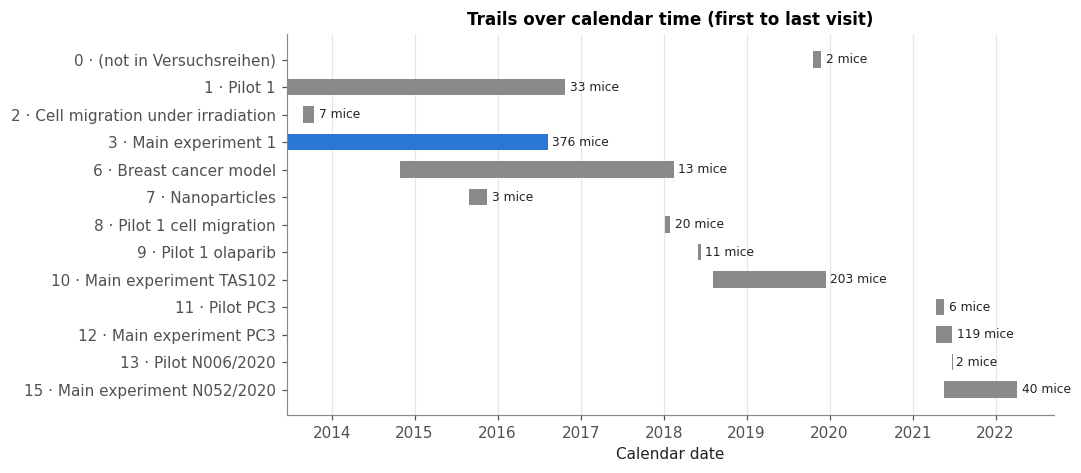

In [9]:
span = trail_overview.dropna(subset=["first_visit"]).sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
for y, (trail, row) in enumerate(span.iterrows()):
    start, end = mdates.date2num(row["first_visit"]), mdates.date2num(row["last_visit"])
    color = THERAPY_COLORS[1] if trail == TRAIL else MUTED
    ax.barh(y, max(end - start, 5), left=start, height=0.6, color=color)
    ax.text(end + 20, y, f"{row['mice']} mice", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(span)), [f"{t} · {n}" for t, n in zip(span.index, span["name"])])
ax.xaxis_date()
ax.grid(axis="y", visible=False)
ax.set_title("Trails over calendar time (first to last visit)")
ax.set_xlabel("Calendar date")
plt.show()

## A3. Animals across trails
Counts of mice per trail by role (abbreviations as in `Rollen`: RT radiotherapy, RChT radiochemotherapy,
ChT chemotherapy, K/E controls at the start/end, B observation without therapy, KT no local tumour or
early termination, OP surgery, V pilot, – unassigned), sex, strain and cause of death.

In [10]:
pd.DataFrame(ROLE_NAMES.items(), columns=["role", "meaning"]).set_index("role")

,meaning
role,
0,"Unassigned (role 0, not in lookup)"
1,RT: radiotherapy
2,RChT: radiochemotherapy
3,ChT: chemotherapy
4,K: control animal at the start
5,E: control animal at the end
6,V: pilot experiment
7,B: observation without therapy
8,"KT: no local tumour despite injection, or early termination"


In [11]:
display(named_crosstab(mice["trail"], mice["role_abbr"].rename("role")))
display(named_crosstab(mice["trail"], mice["sex"]))
display(named_crosstab(mice["trail"], mice["strain"]))
display(named_crosstab(mice["trail"], mice["death_cause"].fillna("(no death record)")))

role,B,ChT,E,K,KT,OP,RChT,RT,V,–,Total
trail,,,,,,,,,,,
0,0,0,0,0,0,0,0,1,0,1,2
1,2,21,0,0,0,0,9,1,0,0,33
2,0,0,0,0,0,0,0,7,0,0,7
3,3,54,73,54,38,18,61,73,0,2,376
4,0,0,0,0,0,0,0,6,0,0,6
5,0,0,0,0,0,0,0,0,2,0,2
6,0,0,0,0,0,0,1,12,0,0,13
7,0,0,0,0,0,0,0,3,0,0,3
8,3,0,6,6,0,0,0,5,0,0,20


sex,female,male,Total
trail,,,
0,1,1,2
1,8,25,33
2,0,7,7
3,139,237,376
4,6,0,6
5,2,0,2
6,12,1,13
7,3,0,3
8,0,20,20


strain,Balb/c,C57Bl/6,FVB/N-Tg(MMTV-PyVT),NMRI-Foxn1nu,NSG NOD.Cg-Prkdcscid,PFP/RAG2,SCID,SCID Select,Total
trail,,,,,,,,,
0,0,0,0,0,1,1,0,0,2
1,0,0,0,0,0,5,28,0,33
2,0,0,0,0,0,0,4,3,7
3,0,0,0,0,0,95,281,0,376
4,6,0,0,0,0,0,0,0,6
5,0,0,0,0,0,2,0,0,2
6,0,0,12,0,0,0,1,0,13
7,0,0,0,0,0,3,0,0,3
8,0,0,0,0,0,0,20,0,20


death_cause,(no death record),Death directly after surgery,Experiment ended as planned,Killed: poor general condition,Killed: tumour ulceration,Poor general condition / suspected lymphoma,Spontaneous death,Unknown,Unknown: disposed of by animal care,Total
trail,,,,,,,,,,
0,0,0,1,0,0,0,0,1,0,2
1,2,0,3,12,1,4,8,3,0,33
2,7,0,0,0,0,0,0,0,0,7
3,0,2,296,40,1,4,11,17,5,376
4,6,0,0,0,0,0,0,0,0,6
5,0,0,1,0,1,0,0,0,0,2
6,0,0,12,0,0,0,0,1,0,13
7,0,0,3,0,0,0,0,0,0,3
8,0,0,20,0,0,0,0,0,0,20


## A4. Measurements and treatments across trails
Visits per trail and per mouse and the body weight per visit. Weights of 0 g and above 100 g are
entry errors (see A5) and are left out of the boxplot.

,visits,mice_with_visits,visits_per_mouse,weight_g
trail,,,,
0,35,1,35 [35–35],21.4 [20.9–21.7]
1,1217,33,25 [7–70],27.4 [24.5–29.1]
2,7,7,1 [1–1],27.0 [22.0–28.0]
3,7047,376,15 [10–19],25.1 [22.5–27.6]
6,13,13,1 [1–1],20.4 [18.6–21.9]
7,39,3,13 [13–13],22.2 [21.6–22.9]
8,428,20,23 [19–24],24.9 [23.6–26.1]
9,11,11,1 [1–1],32.5 [27.8–35.2]
10,7159,202,33 [25–43],23.9 [21.7–27.5]


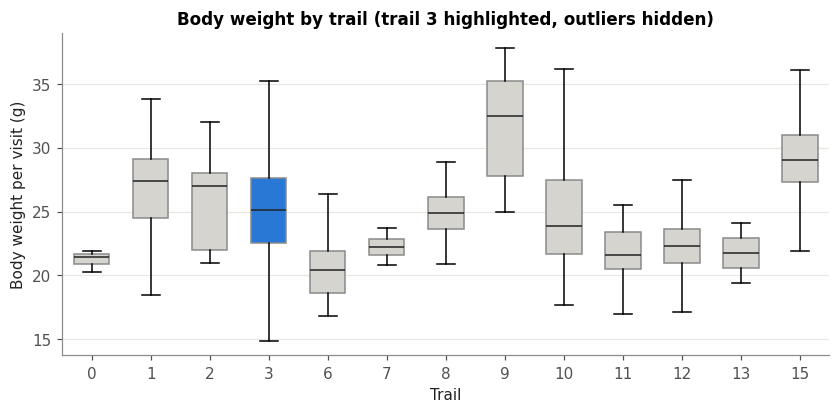

In [12]:
plausible = visits[(visits["weight"] > 0) & (visits["weight"] <= 100)]
visit_stats = visits.dropna(subset=["trail"]).groupby("trail").agg(
    visits=("id", "size"),
    mice_with_visits=("id", "nunique"),
)
visit_stats["visits_per_mouse"] = visits.groupby(["trail", "id"]).size().groupby("trail").apply(median_iqr)
visit_stats["weight_g"] = plausible.groupby("trail")["weight"].apply(median_iqr, digits=1)
visit_stats.index = visit_stats.index.astype(int)
display(visit_stats)

order = [t for t in sorted(plausible["trail"].dropna().unique())]
fig, ax = plt.subplots(figsize=(9, 3.8))
data = [plausible.loc[plausible["trail"] == t, "weight"] for t in order]
box = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False, medianprops={"color": INK})
for patch, t in zip(box["boxes"], order):
    patch.set_facecolor(THERAPY_COLORS[1] if t == TRAIL else "#d5d4cf")
    patch.set_edgecolor(MUTED)
ax.set_xticks(range(1, len(order) + 1), [int(t) for t in order])
ax.set_xlabel("Trail")
ax.set_ylabel("Body weight per visit (g)")
ax.set_title("Body weight by trail (trail 3 highlighted, outliers hidden)")
ax.grid(axis="x", visible=False)
plt.show()

Trail 3 is by far the largest trail: about 45% of all mice and a third of all visits. Trails 10
(TAS102) and 12 (PC3) are the next largest; most other trails are small pilots.

In [13]:
treatments_per_trail = pd.DataFrame({
    "RT fractions": radio.groupby("trail").size(),
    "mice with RT": radio.groupby("trail")["id"].nunique(),
    "ChT administrations": chemo.groupby("trail").size(),
    "mice with ChT": chemo.groupby("trail")["id"].nunique(),
    "surgeries": surgery.groupby("trail").size(),
    "anaesthesias": anaesthesia.groupby("trail").size(),
}).fillna(0).astype(int)
treatments_per_trail["RT protocols"] = radio.groupby("trail")["concept"].agg(lambda s: ", ".join(sorted(s.dropna().unique())))
treatments_per_trail["ChT drugs"] = chemo.groupby("trail")["drug"].agg(lambda s: ", ".join(sorted(s.dropna().unique())))
treatments_per_trail.index = treatments_per_trail.index.astype(int)
treatments_per_trail.fillna("")

,RT fractions,mice with RT,ChT administrations,mice with ChT,surgeries,anaesthesias,RT protocols,ChT drugs
trail,,,,,,,,
0,3,1,0,0,0,3,d1-5 2.0 Gy,
1,36,8,84,28,0,97,"d1-5 10,0 Gy","Cisplatin, Docetaxel, Etoposid"
2,7,7,0,0,0,7,"d1 10,0 Gy, d1 15,0 Gy",
3,666,134,192,116,19,867,"d1-5 10,0 Gy","Cisplatin, Docetaxel"
4,9,6,0,0,0,9,"d1 6 Gy - Femora, d1 6 Gy - Mamma",
6,12,12,0,0,0,12,"Mamma01 d1 3,0 Gy, Mamma02 d1 10,0 Gy",
7,15,3,0,0,0,15,"d1-5 10,0 Gy",
8,15,5,0,0,0,15,"d1 10,0 Gy, d1-2 10.0 Gy, d1-3 10.0 Gy, d1-4 10.0 Gy, d1-5 10,0 Gy",
9,8,8,6,6,0,8,d1 2.0 Gy,Olaparib


## A5. Data-quality issues in the database
Counted over the whole database. Most of them are removed by the cohort preprocessing (Part C); the
column *in trail 3, RT/RChT/ChT* shows how many concern the 188 candidate mice of the study cohort.

In [14]:
candidates = mice[(mice["trail"] == TRAIL) & mice["role"].isin(COHORT_ROLES)]["id"]
v_birth = visits.merge(mice[["id", "birth", "injection"]], on="id", how="left")
v_birth["trail_start"] = v_birth["trail"].map(pd.to_datetime(vr["VersuchStart"], errors="coerce"))
same_day = visits.dropna(subset=["date"]).groupby(["id", "date"]).size()
issues = [
    ("Mice in trail 0, which is not in Versuchsreihen", mice["trail"].eq(0), "mice"),
    ("Mice without a death date", mice["death"].isna(), "mice"),
    ("Mice with an injection date before birth", mice["injection"] < mice["birth"], "mice"),
    ("Visits with an invalid date (e.g. 0000-00-00)", visits["date"].isna(), "visits"),
    ("Visits of a mouse not in Versuchstiere", visits["trail"].isna(), "visits"),
    ("Visits before the birth of the mouse", v_birth["date"] < v_birth["birth"], "visits"),
    ("Visits before the start of the trail", v_birth["date"] < v_birth["trail_start"], "visits"),
    ("Visits with weight 0 g", visits["weight"].eq(0), "visits"),
    ("Visits with weight > 100 g", visits["weight"].gt(100), "visits"),
    ("Visits with tumour volume > 100 cm³", visits["tumour_volume"].gt(100), "visits"),
    ("Visits where the total score is not the sum of the sub-scores",
     visits["score"].ne(visits[["kg_points", "az_points", "vh_points", "tu_points"]].sum(axis=1)), "visits"),
]
rows = []
for issue, mask, unit in issues:
    ids = (mice if unit == "mice" else visits)["id"]
    rows.append({"issue": issue, "unit": unit, "count": int(mask.sum()), f"in trail {TRAIL}, RT/RChT/ChT": int((mask & ids.isin(candidates)).sum())})
dup_days = same_day[same_day > 1]
rows.append({"issue": "Mouse-days with more than one visit", "unit": "mouse-days", "count": len(dup_days),
             f"in trail {TRAIL}, RT/RChT/ChT": int(dup_days.index.get_level_values("id").isin(candidates).sum())})
rows.append({"issue": "Trails without a start date", "unit": "trails", "count": int(vr["VersuchStart"].isna().sum()),
             f"in trail {TRAIL}, RT/RChT/ChT": 0})
rows.append({"issue": "Trails without mice", "unit": "trails", "count": int((~vr.index.isin(mice["trail"])).sum()),
             f"in trail {TRAIL}, RT/RChT/ChT": 0})
pd.DataFrame(rows)

,issue,unit,count,"in trail 3, RT/RChT/ChT"
0,"Mice in trail 0, which is not in Versuchsreihen",mice,2,0
1,Mice without a death date,mice,63,0
2,Mice with an injection date before birth,mice,2,0
3,Visits with an invalid date (e.g. 0000-00-00),visits,5,0
4,Visits of a mouse not in Versuchstiere,visits,1,0
5,Visits before the birth of the mouse,visits,29,0
6,Visits before the start of the trail,visits,139,36
7,Visits with weight 0 g,visits,10,1
8,Visits with weight > 100 g,visits,11,1
9,Visits with tumour volume > 100 cm³,visits,6,1


# Part B: trail 3, the experiment behind the cohort

## B1. Design
Trail 3 ("Hauptversuch 1", main experiment 1) belongs to project G14/13. Human tumour cells were
injected subcutaneously into immunodeficient mice (xenografts). The mice were then allocated to
radiotherapy, chemotherapy, radiochemotherapy, surgery or control groups, and followed with regular
visits until they were killed. The cell lines carry an RGB marking (red/green/blue fluorescent
labels), which serves the second aim of the trail, the clonal selection of metastases.

In [15]:
m3 = mice[mice["trail"] == TRAIL].copy()
display(trail_overview.loc[[TRAIL], ["name", "aim", "licence", "project", "start", "first_visit", "last_visit", "mice", "visits"]].T)
fact(f"Mice in trail {TRAIL}", len(m3))

cohorts3 = tables["Kohorten"].query("Versuchsreihe == @TRAIL").assign(
    cell_line=lambda x: x["NameZelllinie"].map(lookup("Tumorzelllinien", "IdZelllinie", "NameZelllinie")),
    host_strain=lambda x: x["Tiertyp"].map(lookup("Tiertypen", "IdTiertyp", "Tiertyp")),
)
cohorts3["tumour_type"] = cohorts3["cell_line"].map(TUMOUR_TYPES)
cohorts3["mice"] = cohorts3["KohorteName"].map(m3["cohort"].value_counts()).fillna(0).astype(int)
cohorts3[["IdKohorte", "KohorteName", "cell_line", "tumour_type", "host_strain", "mice", "Bemerkung"]]

trail,3
name,Main experiment 1
aim,"effect of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models; clonal selection of metastases"
licence,G14/13
project,"Influence of radiotherapy, chemotherapy, simultaneous radiochemotherapy and surgery on metastasis in xenograft mouse models"
start,2013-08-03
first_visit,2013-06-17 00:00:00
last_visit,2016-08-08 00:00:00
mice,376
visits,7047


,IdKohorte,KohorteName,cell_line,tumour_type,host_strain,mice,Bemerkung
6,7,OH1 RGB,OH-1 RGB,small-cell lung cancer (SCLC),SCID,175,Hauptversuch OH1 RGB
7,8,H69 RGB,H69 RGB,small-cell lung cancer (SCLC),SCID,103,Hauptversuch H69 RGB
8,9,LNCaP RGB,LNCaP RGB,prostate cancer (androgen-sensitive),PFP/RAG2,95,Hauptversuch LNCaP RGB
9,10,PC3 RGB,PC-3 RGB,prostate cancer (androgen-independent),PFP/RAG2,0,Hauptversuch PC3 RGB
10,11,MRT-Kontrolltiere,NaN,NaN,NaN,2,Tiere ohne Tumorzellen


Mice of trail 3 outside these cohorts belong to injection batches of other cohorts (see the table
below). Injection site and number of tumour records per mouse:

In [16]:
display(primary[primary["IdTier"].isin(m3["id"])]["site"].value_counts().rename("tumour records").to_frame())
display(m3["tumours"].value_counts().sort_index().rename("mice").rename_axis("tumour records per mouse").to_frame())

batches3 = (
    m3.groupby("batch")
    .agg(cohort=("cohort", "first"), cell_line=("cell_line", "first"), mice=("id", "size"),
         roles=("role_abbr", lambda r: ", ".join(f"{k} {v}" for k, v in r.value_counts().items())))
    .join(batches[["Datum", "Bemerkung"]])
    .rename(columns={"Datum": "date", "Bemerkung": "remark"})
    .sort_values("date")
)
batches3

,tumour records
site,
"s.c., right flank (injection)",323
"s.c., right side, end of thorax (injection)",70


,mice
tumour records per mouse,
0,4
1,351
2,21


,cohort,cell_line,mice,roles,date,remark
batch,,,,,,
57,Kooperation Zellmigration,OH-1 RGB,1,KT 1,2013-07-24,Vorzeitiger Therapieabbruch
8,OH1 RGB,OH-1 RGB,25,"ChT 5, RChT 5, RT 5, E 5, K 4, B 1",2013-09-23,Hauptversuch OH1 01
9,H69 RGB,H69 RGB,8,"RT 2, E 2, RChT 2, K 1, ChT 1",2013-10-07,Hauptversuch H69 01
10,LNCaP RGB,LNCaP RGB,25,"E 5, RT 5, K 5, ChT 5, RChT 5",2013-10-14,Hauptversuch LNCaP 01
11,H69 RGB,H69 RGB,5,"RChT 2, RT 1, E 1, ChT 1",2013-10-21,Hauptversuch H69 02
12,OH1 RGB,OH-1 RGB,24,"E 6, RChT 5, ChT 5, RT 5, K 3",2013-10-28,Hauptversuch OH1 02
13,H69 RGB,H69 RGB,10,"ChT 2, RT 2, E 2, RChT 2, K 2",2013-11-25,Hauptversuch H69 03
14,H69 RGB,H69 RGB,21,"E 6, ChT 4, RT 4, RChT 4, K 3",2013-12-02,Hauptversuch H69 04
15,H69 RGB,H69 RGB,23,"E 5, ChT 5, RT 5, RChT 5, K 3",2013-12-16,Hauptversuch H69 05


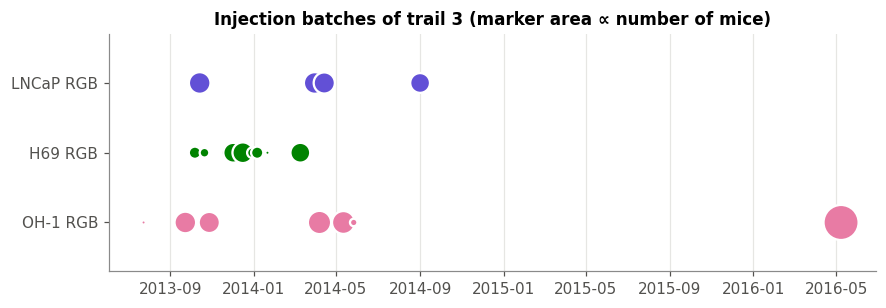

In [17]:
fig, ax = plt.subplots(figsize=(9, 2.8))
b = batches3.dropna(subset=["cell_line"]).assign(date=lambda x: pd.to_datetime(x["date"]))
lines = [c for c in CELL_COLORS if c in set(b["cell_line"])]
for y, line in enumerate(lines):
    sub = b[b["cell_line"] == line]
    ax.scatter(sub["date"], [y] * len(sub), s=sub["mice"] * 8, color=CELL_COLORS[line], edgecolor="white", linewidth=1.5, zorder=3)
ax.set_yticks(range(len(lines)), lines)
ax.set_ylim(-0.7, len(lines) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_title("Injection batches of trail 3 (marker area ∝ number of mice)")
plt.show()

Three human cell lines were used: the two small-cell lung cancer lines OH-1 and H69 in SCID mice
and the prostate cancer line LNCaP in (male) PFP/RAG2 mice. The PC-3 cohort of the trail has no
mice. Most batches were injected between September 2013 and September 2014. One late OH-1 batch
followed in May 2016 ("main experiment OH1 with surgery").

## B2. Group allocation
The role of a mouse is its treatment group. Only the three treated groups RT, RChT and ChT are in the
study cohort. The others are left out because they received no radio- or chemotherapy (controls K
and E, observation B), had surgery instead (OP), did not grow a local tumour or were terminated early
(KT), or were never assigned (role 0).

In [18]:
display(named_crosstab(m3["role_abbr"].rename("role"), m3["cell_line"].fillna("(none)")))
display(named_crosstab(m3["role_abbr"].rename("role"), m3["sex"]))
display(named_crosstab(m3["role_abbr"].rename("role"), m3["strain"]))
display(named_crosstab(m3["cell_line"].fillna("(none)"), m3["strain"]))
display(named_crosstab(m3["cell_line"].fillna("(none)"), m3["sex"]))

cell_line,(none),H69 RGB,LNCaP RGB,OH-1 RGB,Total
role,,,,,
B,2,0,0,1,3
ChT,0,15,19,20,54
E,0,24,19,30,73
K,0,10,18,26,54
KT,0,21,0,17,38
OP,0,0,0,18,18
RChT,0,17,20,24,61
RT,0,16,19,38,73
–,0,0,0,2,2


sex,female,male,Total
role,,,
B,0,3,3
ChT,18,36,54
E,28,45,73
K,18,36,54
KT,17,21,38
OP,8,10,18
RChT,19,42,61
RT,29,44,73
–,2,0,2


strain,PFP/RAG2,SCID,Total
role,,,
B,0,3,3
ChT,19,35,54
E,19,54,73
K,18,36,54
KT,0,38,38
OP,0,18,18
RChT,20,41,61
RT,19,54,73
–,0,2,2


strain,PFP/RAG2,SCID,Total
cell_line,,,
(none),0,2,2
H69 RGB,0,103,103
LNCaP RGB,95,0,95
OH-1 RGB,0,176,176
Total,95,281,376


sex,female,male,Total
cell_line,,,
(none),0,2,2
H69 RGB,49,54,103
LNCaP RGB,0,95,95
OH-1 RGB,90,86,176
Total,139,237,376


## B3. Treatment protocols
### Radiotherapy
Planned protocol per mouse (`Versuchstiere.RTKonzept`) and the fractions actually recorded in
`Bestrahlungen`.

In [19]:
display(tables["RTKonzepte"].set_index("IdRTKonzept").loc[
    sorted(set(m3["rt_concept"]) - {0}), ["RTKonzept", "Einzeldosis", "Enddosis", "Fraktionen", "FrakTag", "FrakWo", "Qualitaet", "Bemerkung"]
].rename(columns={"Einzeldosis": "dose per fraction (Gy)", "Enddosis": "total dose (Gy)", "Fraktionen": "fractions",
                  "FrakTag": "fractions/day", "FrakWo": "fractions/week", "Qualitaet": "beam"}))

r3 = radio[radio["IdTier"].isin(m3["id"])]
rt_per_mouse = r3.groupby("id").agg(fractions=("IdBestrahlung", "size"), dose_gy=("DosisIst", "sum"),
                                    first_rt=("date", "min"), last_rt=("date", "max"))
rt_per_mouse["days_first_to_last"] = (rt_per_mouse["last_rt"] - rt_per_mouse["first_rt"]).dt.days
m3 = m3.join(rt_per_mouse, on="id")
display(m3.groupby("role_abbr").agg(
    mice=("id", "size"),
    with_RT=("fractions", "count"),
    fractions=("fractions", lambda x: x.value_counts().sort_index().to_dict()),
    total_dose_Gy=("dose_gy", lambda x: x.value_counts().sort_index().to_dict()),
    days_first_to_last_fraction=("days_first_to_last", lambda x: x.value_counts().sort_index().to_dict()),
))
print("Delivered dose per fraction (Gy):", r3["DosisIst"].value_counts().to_dict())

,RTKonzept,dose per fraction (Gy),total dose (Gy),fractions,fractions/day,fractions/week,beam,Bemerkung
IdRTKonzept,,,,,,,,
1,"d1-5 10,0 Gy",10,50,5,1,5,200 kV,Standard 5 x 10 Gy


,mice,with_RT,fractions,total_dose_Gy,days_first_to_last_fraction
role_abbr,,,,,
B,3,0,{},{},{}
ChT,54,0,{},{},{}
E,73,0,{},{},{}
K,54,0,{},{},{}
KT,38,0,{},{},{}
OP,18,0,{},{},{}
RChT,61,61,{5.0: 61},{50.0: 61},{4.0: 61}
RT,73,73,"{1.0: 1, 5.0: 72}","{10.0: 1, 50.0: 72}","{0.0: 1, 4.0: 72}"
–,2,0,{},{},{}


Delivered dose per fraction (Gy): {10: 666}


### Chemotherapy
Drug and protocol per cell line, number of administrations per mouse and the timing relative to the
first radiotherapy fraction for the RChT group.

In [20]:
c3 = chemo[chemo["IdTier"].isin(m3["id"])].merge(m3[["id", "role_abbr", "cell_line"]], on="id")
display(tables["ChTKonzepte"].set_index("IdChTKonzept").loc[sorted(set(c3["IdChTKonzept"])), ["NameChTKonzept", "ChTKonz1", "ChTTage1", "Bemerkung"]]
        .rename(columns={"NameChTKonzept": "protocol", "ChTKonz1": "dose (mg/kg)", "ChTTage1": "days"}))
display(pd.crosstab([c3["cell_line"], c3["drug"]], c3["role_abbr"].rename("role"), margins=True, margins_name="Total")
        .rename(columns=lambda c: f"{c} (administrations)"))
cht_per_mouse = c3.groupby("id").agg(administrations=("IdChemo", "size"), drug=("drug", "first"), route=("route", "first"),
                                     first_cht=("date", "min"))
m3 = m3.join(cht_per_mouse, on="id")
display(m3.dropna(subset=["drug"]).groupby(["role_abbr", "drug"]).agg(
    mice=("id", "size"),
    administrations=("administrations", lambda x: x.value_counts().sort_index().to_dict()),
    route=("route", lambda x: ", ".join(x.unique())),
))

rcht = m3[m3["role"] == 2]
lag = (rcht["first_cht"] - rcht["first_rt"]).dt.days
print("RChT: days from the first RT fraction to the first ChT administration:", lag.value_counts().sort_index().to_dict())

,protocol,dose (mg/kg),days,Bemerkung
IdChTKonzept,,,,
2,Doctaxel 20 mg/kg d1-8-15,20,3,None
5,Cisplatin 6mg/kg d1,6,1,


,role,ChT (administrations),RChT (administrations),RT (administrations),Total (administrations)
cell_line,drug,,,,
H69 RGB,Cisplatin,15,17,0,32
LNCaP RGB,Docetaxel,57,58,1,116
OH-1 RGB,Cisplatin,20,24,0,44
Total,,92,99,1,192


mice    administrations route
role_abbr drug                                    
ChT       Cisplatin    35          {1.0: 35}  i.p.
          Docetaxel    19          {3.0: 19}  i.p.
RChT      Cisplatin    41          {1.0: 41}  i.p.
          Docetaxel    20  {2.0: 2, 3.0: 18}  i.p.
RT        Docetaxel     1           {1.0: 1}  i.p.

RChT: days from the first RT fraction to the first ChT administration: {0: 61}


**Protocols in short.**
- **RT:** 5 × 10 Gy (50 Gy) to the tumour on five consecutive days (200 kV).
- **ChT:** depends on the tumour type. The SCLC lines (OH-1, H69) got cisplatin 6 mg/kg i.p. once; LNCaP got
  docetaxel 20 mg/kg i.p. on days 1, 8 and 15.
- **RChT:** both. Chemotherapy starts on the day of the first RT fraction (simultaneous).

### Deviations from the planned protocol
Mice whose recorded treatment does not match their role.

In [21]:
expected_rt = m3["role"].isin([1, 2])
expected_cht = m3["role"].isin([2, 3])
deviation = m3[
    (expected_rt & (m3["fractions"].fillna(0) != 5))
    | (~expected_rt & m3["fractions"].notna())
    | (expected_cht & m3["administrations"].isna())
    | (~expected_cht & m3["administrations"].notna())
].assign(in_study_cohort=lambda x: x["id"].isin(df["item_id"]))
deviation[["id", "role_abbr", "cell_line", "fractions", "drug", "administrations", "death_cause", "in_study_cohort", "note"]]

,id,role_abbr,cell_line,fractions,drug,administrations,death_cause,in_study_cohort,note
12,13,RT,LNCaP RGB,5.0,Docetaxel,1.0,Experiment ended as planned,True,Tier hat am 21.10.2013 versehentlich einmal ChT erhalten.
159,160,RT,H69 RGB,1.0,NaN,NaN,Killed: poor general condition,True,Zunehmende Beinlähmung


Translation of the notes: mouse 13 "received ChT once by mistake on 21 Oct 2013"; mouse 160
"increasing paralysis of the legs" (only 1 of 5 fractions). Both stay in the study cohort, as RT.

### Anaesthesia
Recorded anaesthesia sessions per mouse, by role.

In [22]:
a3 = anaesthesia[anaesthesia["IdTier"].isin(m3["id"])].merge(m3[["id", "role_abbr"]], on="id")
display(pd.crosstab(a3["role_abbr"].rename("role"), a3["Narkotikum"], margins=True, margins_name="Total"))
display(a3.groupby(["role_abbr", "id"]).size().groupby("role_abbr").apply(median_iqr).rename("sessions per mouse").to_frame())

Narkotikum,CO2O2,Isofluran,Rompun/Ketanest i.p.,Total
role,,,,
ChT,33,54,0,87
E,0,0,1,1
OP,0,0,18,18
RChT,32,367,0,399
RT,1,361,0,362
Total,66,782,19,867


,sessions per mouse
role_abbr,
ChT,1 [1–3]
E,1 [1–1]
OP,1 [1–1]
RChT,6 [6–7]
RT,5 [5–5]


## B4. Ages
Age at tumour injection, at the first visit and at death, in weeks. The age at injection is the
usual way to describe the animals in a methods section.

In [23]:
first_visit = known_visits.groupby("id")["date"].min()
m3["first_visit"] = m3["id"].map(first_visit)
m3["age_injection_wk"] = (m3["injection"] - m3["birth"]).dt.days / 7
m3["age_first_visit_wk"] = (m3["first_visit"] - m3["birth"]).dt.days / 7
m3["age_death_wk"] = (m3["death"] - m3["birth"]).dt.days / 7
ages = m3.groupby("role_abbr").agg(
    mice=("id", "size"),
    age_at_injection_wk=("age_injection_wk", lambda x: median_iqr(x, 1)),
    age_at_first_visit_wk=("age_first_visit_wk", lambda x: median_iqr(x, 1)),
    age_at_death_wk=("age_death_wk", lambda x: median_iqr(x, 1)),
)
display(ages)
display(m3.groupby("cell_line").agg(mice=("id", "size"), age_at_injection_wk=("age_injection_wk", lambda x: median_iqr(x, 1)),
                                    age_at_death_wk=("age_death_wk", lambda x: median_iqr(x, 1))))
print("Implausible ages at injection (< 3 weeks):")
display(m3.loc[m3["age_injection_wk"] < 3, ["id", "role_abbr", "birth", "injection", "first_visit", "death"]])

,mice,age_at_injection_wk,age_at_first_visit_wk,age_at_death_wk
role_abbr,,,,
B,3,16.7 [16.7–16.7],27.9 [22.2–27.9],27.9 [23.2–27.9]
ChT,54,18.7 [16.7–20.9],18.6 [16.6–20.7],26.7 [22.7–29.9]
E,73,18.6 [16.7–20.9],18.6 [15.6–20.7],25.1 [22.6–29.6]
K,54,18.6 [17.0–20.9],18.4 [15.6–20.7],24.1 [20.7–29.0]
KT,38,17.4 [16.7–18.6],16.6 [15.6–18.6],28.3 [24.4–55.3]
OP,18,17.4 [17.4–17.4],15.6 [15.6–15.6],21.6 [20.4–21.6]
RChT,61,18.7 [16.7–21.7],18.6 [16.6–20.7],28.1 [23.9–32.7]
RT,73,18.6 [17.4–20.9],18.4 [15.6–20.6],25.6 [21.6–29.6]
–,2,37.7 [37.7–37.7],37.6 [37.6–37.6],40.1 [39.8–40.3]


,mice,age_at_injection_wk,age_at_death_wk
cell_line,,,
H69 RGB,103,19.6 [18.6–19.6],26.6 [24.7–28.9]
LNCaP RGB,95,16.6 [14.0–21.7],28.4 [24.6–31.4]
OH-1 RGB,176,17.4 [17.4–33.7],22.7 [20.7–36.2]


Implausible ages at injection (< 3 weeks):


,id,role_abbr,birth,injection,first_visit,death
0,1,E,2013-10-12,2013-06-18,2013-06-17,2013-11-05


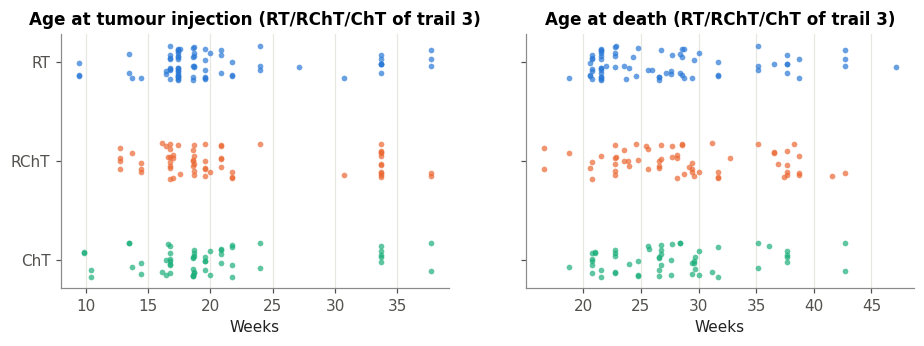

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
in_cohort = m3[m3["role"].isin(COHORT_ROLES)]
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, len(in_cohort))
for ax, column, title in zip(axes, ["age_injection_wk", "age_death_wk"], ["Age at tumour injection", "Age at death"]):
    for y, role in enumerate(COHORT_ROLES):
        mask = (in_cohort["role"] == role).to_numpy()
        ax.scatter(in_cohort.loc[mask, column], y + jitter[mask], s=14, color=THERAPY_COLORS[role], alpha=0.7, linewidth=0)
    ax.set_title(f"{title} (RT/RChT/ChT of trail 3)")
    ax.set_xlabel("Weeks")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(COHORT_ROLES)), [THERAPY_ABBR[r] for r in COHORT_ROLES])
axes[0].invert_yaxis()
plt.show()

## B5. Outcomes: causes of death and time on study
In trail 3 almost every mouse was killed at a planned endpoint ("experiment ended as planned"), so
the end of a weight series is mostly set by the protocol, not by the disease. Few mice died
spontaneously or were killed early because of their condition.

In [25]:
display(named_crosstab(m3["death_cause"].fillna("(none)"), m3["role_abbr"].rename("role")))
display(named_crosstab(m3["kill_method"].fillna("(none)"), m3["role_abbr"].rename("role")))
fact(f"Trail {TRAIL}: mice killed at the planned end of the experiment",
     n_pct(int((m3["death_cause"] == DEATH_CAUSES[2]).sum()), len(m3)))

role,B,ChT,E,K,KT,OP,RChT,RT,–,Total
death_cause,,,,,,,,,,
Death directly after surgery,0,0,0,0,0,2,0,0,0,2
Experiment ended as planned,0,52,66,54,10,12,42,60,0,296
Killed: poor general condition,2,0,7,0,16,4,6,5,0,40
Killed: tumour ulceration,0,1,0,0,0,0,0,0,0,1
Poor general condition / suspected lymphoma,0,0,0,0,4,0,0,0,0,4
Spontaneous death,1,1,0,0,2,0,4,3,0,11
Unknown,0,0,0,0,6,0,4,5,2,17
Unknown: disposed of by animal care,0,0,0,0,0,0,5,0,0,5
Total,3,54,73,54,38,18,61,73,2,376


role,B,ChT,E,K,KT,OP,RChT,RT,–,Total
kill_method,,,,,,,,,,
CO2,0,0,4,1,0,0,0,0,0,5
Cervical dislocation,2,0,0,0,4,0,0,1,0,7
Final blood sampling,0,50,66,47,26,16,45,62,0,312
Final ketamine anaesthesia,0,3,3,5,0,0,3,2,0,16
Spontaneous death (not killed),1,1,0,1,8,2,13,8,2,36
Total,3,54,73,54,38,18,61,73,2,376


'296 (79%)'

Time on study from tumour injection to death. Because nearly all deaths are planned, the
Kaplan–Meier curve shows how long the groups were followed, **not** survival in a clinical sense.

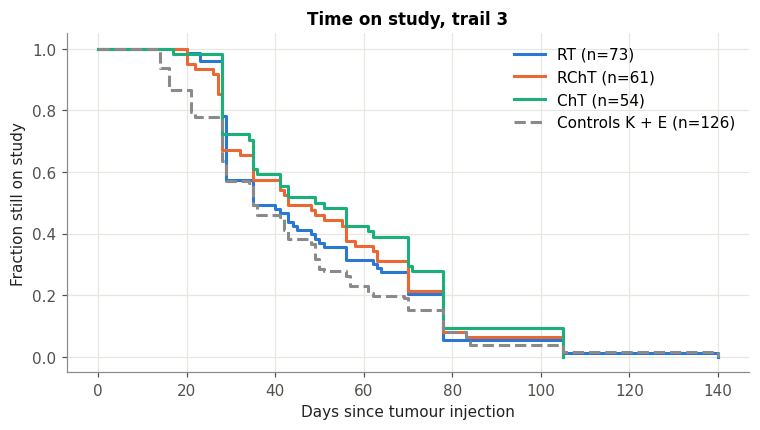

,days from injection to death
role_abbr,
B,13 [13–13]
ChT,50 [28–78]
E,46 [29–70]
K,22 [16–42]
KT,74 [64–268]
OP,29 [21–29]
RChT,43 [28–70]
RT,35 [29–70]
–,16 [15–18]


In [26]:
m3["days_on_study"] = (m3["death"] - m3["injection"]).dt.days
fig, ax = plt.subplots(figsize=(8, 4))
curves = [(r, THERAPY_ABBR[r], THERAPY_COLORS[r], "-") for r in COHORT_ROLES] + [((4, 5), "Controls K + E", MUTED, "--")]
for roles, label, color, style in curves:
    sub = m3[m3["role"].isin(np.atleast_1d(roles))].dropna(subset=["days_on_study"])
    sf = SurvfuncRight(sub["days_on_study"].to_numpy(float), np.ones(len(sub)))
    ax.step(np.r_[0, sf.surv_times], np.r_[1, sf.surv_prob], where="post", color=color, linestyle=style,
            label=f"{label} (n={len(sub)})")
ax.set_xlabel("Days since tumour injection")
ax.set_ylabel("Fraction still on study")
ax.set_title("Time on study, trail 3")
ax.legend()
plt.show()
display(m3.groupby("role_abbr")["days_on_study"].apply(median_iqr).rename("days from injection to death").to_frame())

The steps at about 28, 35, 42, 56, 70, 78 and 105 days are the planned end dates of the injection
batches: the curves show the follow-up design more than the course of the disease.

Tumour weight at necropsy (sum over the primary tumour records of a mouse). The tumour is part of the
measured body weight.

,tumour weight
role_abbr,
B,0.00 [0.00–0.00] g
ChT,0.18 [0.01–0.49] g
E,0.38 [0.05–0.99] g
K,0.13 [0.01–0.27] g
KT,0.05 [0.00–0.49] g
OP,0.09 [0.04–0.17] g
RChT,0.02 [0.00–0.08] g
RT,0.03 [0.01–0.11] g
–,0.00 [0.00–0.00] g


,tumour weight
cell_line,
H69 RGB,0.15 [0.00–0.66] g
LNCaP RGB,0.01 [0.00–0.09] g
OH-1 RGB,0.12 [0.04–0.40] g


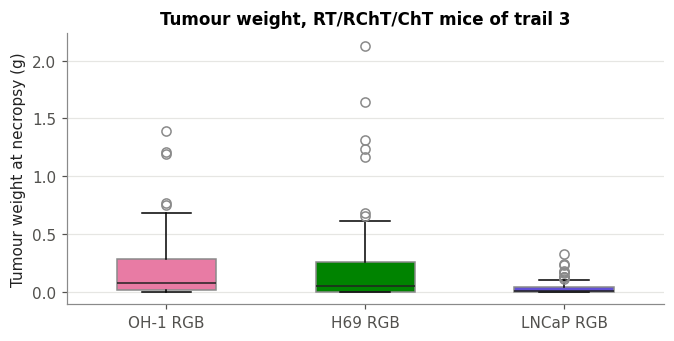

In [27]:
display(m3.groupby("role_abbr")["tumour_weight"].apply(lambda x: median_iqr(x, 2, " g")).rename("tumour weight").to_frame())
display(m3.groupby("cell_line")["tumour_weight"].apply(lambda x: median_iqr(x, 2, " g")).rename("tumour weight").to_frame())
fig, ax = plt.subplots(figsize=(7, 3.2))
data = [in_cohort.loc[in_cohort["cell_line"] == c, "tumour_weight"].dropna() for c in CELL_COLORS]
box = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops={"color": INK}, flierprops={"markeredgecolor": MUTED})
for patch, c in zip(box["boxes"], CELL_COLORS):
    patch.set_facecolor(CELL_COLORS[c])
    patch.set_edgecolor(MUTED)
ax.set_xticks(range(1, len(CELL_COLORS) + 1), list(CELL_COLORS))
ax.set_ylabel("Tumour weight at necropsy (g)")
ax.set_title("Tumour weight, RT/RChT/ChT mice of trail 3")
ax.grid(axis="x", visible=False)
plt.show()

Tumours of irradiated mice (RT, RChT) are much smaller at necropsy than those of the untreated
controls at the end (E). Most tumours weigh well below 1 g, so at most a few percent of the body
weight, but single tumours reach about 2 g, close to 10% of a 25 g mouse.

## B6. Clinical burden score sheet
At every visit the animal is scored on a burden score sheet (German *Score-Sheet*), with four parts:

| Column | Part | Items |
|---|---|---|
| `KGPunkte` | body weight | loss relative to the reference weight (`KGVerlauf`, %) |
| `AZPunkte` | general condition | fur, body orifices, eyes, posture, muscle tone, hydration, cramps, paralysis, temperature, breathing |
| `VHPunkte` | behaviour | sleep, reaction to blowing and touch, curiosity, social contact, motor function, isolation, pain, apathy, coordination, self-mutilation |
| `TUPunkte` | tumour | tumour volume and ulceration |
| `Score` | total | sum of the four parts |

The weight and tumour points follow fixed thresholds, which can be read off the data:

In [28]:
v3 = visits[visits["id"].isin(m3["id"])].copy()
display(v3.groupby("kg_points")["rel_weight"].agg(["count", "min", "median", "max"])
        .rename_axis("weight points").rename(columns=lambda c: f"relative weight % ({c})"))
display(v3[v3["tumour_volume"] < 100].groupby("tu_points").agg(
    visits=("tumour_volume", "size"), min_volume=("tumour_volume", "min"), max_volume=("tumour_volume", "max"),
    ulcerated=("ulceration", "sum")).rename_axis("tumour points"))

,relative weight % (count),relative weight % (min),relative weight % (median),relative weight % (max)
weight points,,,,
0.0,6297,0.000000,101.937984,949.572650
10.0,312,80.097087,86.200463,89.958159
20.0,74,56.310680,76.995977,79.912664


,visits,min_volume,max_volume,ulcerated
tumour points,,,,
0,4025,0.0000,0.0000,0
5,2996,0.0001,1.0000,0
10,23,1.0800,2.7000,0
25,1,0.0838,0.0838,1


So the weight points are 0 at ≥ 90% of the reference weight, 10 at 80–90% and 20 below 80%
(more than 20% weight loss). The tumour points are 5 up to a volume of 1 and 10 above, so the
volume is recorded in cm³ (ml). A total of 20 points is the level at which such score sheets usually
require ending the experiment; check the threshold in the approved protocol before citing it.

In [29]:
score_per_mouse = v3.groupby("id").agg(max_score=("score", "max"), max_kg_points=("kg_points", "max"), visits=("score", "size"))
m3 = m3.join(score_per_mouse, on="id")
score_table = m3.groupby("role_abbr").agg(
    mice=("id", "size"),
    max_score=("max_score", median_iqr),
    reached_score_20=("max_score", lambda x: n_pct(int((x >= 20).sum()), len(x))),
    reached_weight_points_10=("max_kg_points", lambda x: n_pct(int((x >= 10).sum()), len(x))),
    reached_weight_points_20=("max_kg_points", lambda x: n_pct(int((x >= 20).sum()), len(x))),
)
score_table

,mice,max_score,reached_score_20,reached_weight_points_10,reached_weight_points_20
role_abbr,,,,,
B,3,25 [18–25],2 (67%),1 (33%),0 (0%)
ChT,54,5 [5–15],4 (7%),20 (37%),2 (4%)
E,73,5 [5–5],7 (10%),4 (5%),1 (1%)
K,54,5 [5–5],2 (4%),5 (9%),0 (0%)
KT,38,10 [1–10],7 (18%),15 (39%),2 (5%)
OP,18,5 [5–10],2 (11%),5 (28%),2 (11%)
RChT,61,15 [15–20],18 (30%),47 (77%),18 (30%)
RT,73,15 [5–20],21 (29%),37 (51%),17 (23%)
–,2,5 [2–8],0 (0%),1 (50%),0 (0%)


The weight part dominates the burden of the treated mice. In the RChT group three in four mice
lost at least 10% of their reference weight at some visit, and almost a third reached 20 points
in total.

Tumour volume over time since injection, median and interquartile range per cell line (RT/RChT/ChT
mice). Volumes are averaged per mouse and week first; weeks with fewer than 8 mice are not drawn.

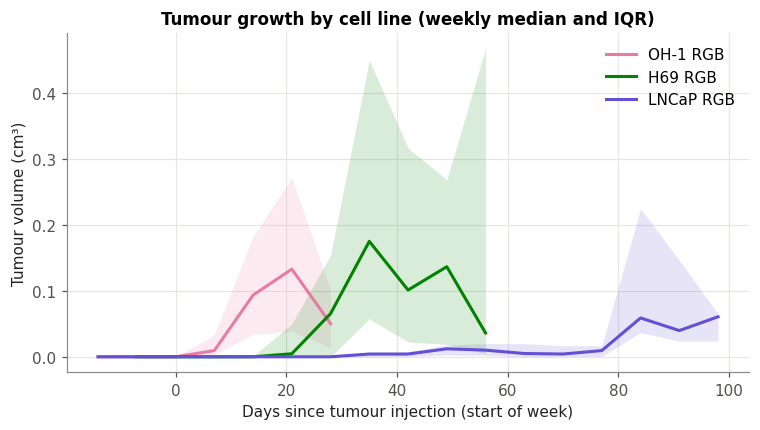

In [30]:
tv = v3[(v3["tumour_volume"] < 100)].merge(in_cohort[["id", "cell_line", "injection"]], on="id")
tv["week"] = (tv["date"] - tv["injection"]).dt.days // 7
fig, ax = plt.subplots(figsize=(8, 4))
for line, color in CELL_COLORS.items():
    per_week = tv[tv["cell_line"] == line].groupby(["week", "id"])["tumour_volume"].mean()
    q = per_week.groupby("week").agg(n="size", q1=lambda x: x.quantile(0.25), med="median", q3=lambda x: x.quantile(0.75))
    q = q[q["n"] >= 8]
    ax.fill_between(q.index * 7, q["q1"], q["q3"], color=color, alpha=0.15, linewidth=0)
    ax.plot(q.index * 7, q["med"], color=color, label=line)
ax.set_xlabel("Days since tumour injection (start of week)")
ax.set_ylabel("Tumour volume (cm³)")
ax.set_title("Tumour growth by cell line (weekly median and IQR)")
ax.legend()
plt.show()

# Part C: the study cohort used for the results

## C1. Cohort derivation
The flow below replays `michael.load_dataset` step by step with the configuration of the results
notebook, so the counts end exactly at the data the models see. First the animals, then the rows.

In [31]:
columns = preprocessing.MOUSE_COLUMNS | {"Geburtsdatum": "birth date", "Sterbedatum": "death date"}
m_all = tables["Versuchstiere"][list(columns)].rename(columns=columns)
starts = tables["Versuchsreihen"][["IdVersuchsreihe", "VersuchStart"]].rename(
    columns={"IdVersuchsreihe": "trail", "VersuchStart": "trail start"})
m_known = m_all.merge(starts, on="trail")
for column in ("birth date", "death date", "trail start"):
    m_known[column] = pd.to_datetime(m_known[column], errors="coerce")
m_trail = m_known[m_known["trail"].isin(config.trails)]
m_role = m_trail[m_trail["role"].isin(config.roles)]
m_dead = m_role[m_role["death date"].notna()]

events_raw = michael._build_events(tables, m_dead).merge(
    m_dead[["id", "trail", "role", "birth date", "trail start"]], on="id")
events_raw["days_since"] = (events_raw["date"] - events_raw["trail start"]).dt.days
events_dated = events_raw[(events_raw["date"] >= events_raw["birth date"]) & (events_raw["days_since"] >= 0)]
events_dated = events_dated.assign(weight=events_dated["weight"].round(2)).sort_values(["id", "days_since"], kind="stable")

per_animal = events_dated.groupby("id").agg(
    events=("event", lambda e: tuple(e.unique())),
    n=("weight", "count"),
    min_weight=("weight", "min"),
    max_weight=("weight", "max"),
).reindex(m_dead["id"])
criteria = pd.DataFrame({
    "treated (RT or ChT recorded)": ~per_animal["events"].map(lambda e: e in michael.UNTREATED or not isinstance(e, tuple)),
    f"at least {config.min_length} weights": per_animal["n"] >= config.min_length,
    "all weights > 0 g": per_animal["min_weight"] > 0,
    f"all weights ≤ {config.max_weight} g": per_animal["max_weight"] <= config.max_weight,
})
keep = criteria[criteria.all(axis=1)].index
assert set(keep) == set(df["item_id"]), "replay does not match load_dataset"

animal_flow = pd.DataFrame([
    ("All animals in the database", len(m_all)),
    ("in a trail listed in Versuchsreihen", len(m_known)),
    (f"in trail {TRAIL} ({TRAIL_NAMES[TRAIL][0]})", len(m_trail)),
    ("with role RT, RChT or ChT", len(m_role)),
    ("with a death date", len(m_dead)),
    ("passing the series filters below (study cohort)", len(keep)),
], columns=["step", "mice"])
display(animal_flow)
excluded = criteria[~criteria.all(axis=1)]
display(Markdown("**Excluded at the last step:**"))
display(excluded.join(per_animal[["n", "min_weight", "max_weight"]]).join(m_dead.set_index("id")["role"].map(ROLE_ABBR)))

,step,mice
0,All animals in the database,843
1,in a trail listed in Versuchsreihen,841
2,in trail 3 (Main experiment 1),376
3,"with role RT, RChT or ChT",188
4,with a death date,188
5,passing the series filters below (study cohort),186


**Excluded at the last step:**

,treated (RT or ChT recorded),at least 5 weights,all weights > 0 g,all weights ≤ 100 g,n,min_weight,max_weight,role
id,,,,,,,,
82,True,True,False,True,16,0.0,20.1,RChT
313,True,True,True,False,10,21.5,222.2,ChT


In [32]:
# Rows: what happens to the records of the cohort mice on the way to one row per mouse and day
kept_events = events_dated[events_dated["id"].isin(keep)]
aligned = michael._align_treatments(kept_events)
counted = aligned.assign(**{t: (aligned["event"] == t).astype(int) for t in michael.TREATMENTS})
per_day = counted.groupby(["id", "date"], as_index=False).agg(
    {"weight": "mean"} | {t: "sum" for t in michael.TREATMENTS}).dropna(subset=["weight"])
assert len(per_day) == len(df), "row replay does not match load_dataset"


def event_counts(events, label):
    counts = events[events["id"].isin(keep)]["event"].value_counts()
    return pd.Series({"step": label, **{e: int(counts.get(e, 0)) for e in ["visit", "radio", "chemo", "surgery", "birth", "death"]},
                      "with weight": int(events[events["id"].isin(keep)]["weight"].notna().sum())})


row_flow = pd.DataFrame([
    event_counts(events_raw, "Records of the cohort mice (visits, treatments, birth, death)"),
    event_counts(events_dated, f"after dropping records before birth / before the trail start ({vr.loc[TRAIL, 'VersuchStart']}) or without a valid date"),
    event_counts(aligned, "each treatment takes over the weight of the nearest visit, which is removed"),
]).set_index("step")
display(row_flow)
dropped = events_raw[events_raw["id"].isin(keep)].drop(events_dated.index, errors="ignore")
print("Dropped by the date filter:", dropped["event"].value_counts().to_dict())
print(f"One row per mouse and day (same-day weights averaged, rows without weight dropped): {len(per_day)} rows = len(df)")
fact("Study cohort: mice", df["item_id"].nunique())
fact("Study cohort: daily weight measurements (rows)", len(df))

,visit,radio,chemo,surgery,birth,death,with weight
step,,,,,,,
"Records of the cohort mice (visits, treatments, birth, death)",3094,661,190,0,186,186,3094
after dropping records before birth / before the trail start (2013-08-03) or without a valid date,3058,661,190,0,70,186,3058
"each treatment takes over the weight of the nearest visit, which is removed",2268,661,190,0,70,186,3119


Dropped by the date filter: {'birth': 116, 'visit': 36}
One row per mouse and day (same-day weights averaged, rows without weight dropped): 3049 rows = len(df)


3049

## C2. Table 1: characteristics of the study cohort
One column per therapy group, as in the results tables. Continuous values are median [interquartile
range]; ages are at the tumour injection. *Baseline weight* is the first measurement of the series.

In [33]:
series = df.sort_values(["item_id", "timestamp"])
per_mouse = series.groupby("item_id").agg(
    role=("role", "first"),
    n=("target", "size"),
    first=("timestamp", "min"),
    last=("timestamp", "max"),
    baseline=("target", "first"),
    last_weight=("target", "last"),
    min_weight=("target", "min"),
    rt_days=("radio", "sum"),
    cht_days=("chemo", "sum"),
    intervention_days=("intervention", "sum"),
)
per_mouse["follow_up_days"] = (per_mouse["last"] - per_mouse["first"]).dt.days
treat_days = series[series["intervention"] > 0].groupby("item_id")["timestamp"]
per_mouse["first_treatment"] = treat_days.min()
per_mouse["last_treatment"] = treat_days.max()
per_mouse["first_treatment_index"] = series.assign(i=series.groupby("item_id").cumcount()).query("intervention > 0").groupby("item_id")["i"].min()
per_mouse = per_mouse.join(m3.set_index("id")[["sex", "strain", "cell_line", "birth", "death", "injection", "death_cause",
                                               "fractions", "dose_gy", "drug", "administrations", "tumour_weight"]])
per_mouse["age_injection_wk"] = (per_mouse["injection"] - per_mouse["birth"]).dt.days / 7
per_mouse["injection_to_treatment"] = (per_mouse["first_treatment"] - per_mouse["injection"]).dt.days
per_mouse["injection_to_death"] = (per_mouse["death"] - per_mouse["injection"]).dt.days
per_mouse["last_to_death"] = (per_mouse["death"] - per_mouse["last"]).dt.days
per_mouse["nadir_pct"] = 100 * per_mouse["min_weight"] / per_mouse["baseline"]


def table_one(pm):
    n = len(pm)
    rows = {"Mice": str(n)}
    for sex in ["male", "female"]:
        rows[f"Sex: {sex}"] = n_pct(int((pm["sex"] == sex).sum()), n)
    for strain in sorted(per_mouse["strain"].dropna().unique()):
        rows[f"Strain: {strain}"] = n_pct(int((pm["strain"] == strain).sum()), n)
    for line in CELL_COLORS:
        rows[f"Cell line: {line.replace(' RGB', '')} ({TUMOUR_TYPES[line]})"] = n_pct(int((pm["cell_line"] == line).sum()), n)
    rows["Age at tumour injection (weeks)"] = median_iqr(pm["age_injection_wk"], 1)
    rows["Baseline weight (g)"] = median_iqr(pm["baseline"], 1)
    rows["Weight at last measurement (g)"] = median_iqr(pm["last_weight"], 1)
    rows["Measurements per mouse"] = f"{median_iqr(pm['n'])}, range {pm['n'].min()}–{pm['n'].max()}"
    rows["Follow-up, first to last measurement (days)"] = median_iqr(pm["follow_up_days"])
    rows["RT: fractions per mouse"] = median_iqr(pm["fractions"]) if pm["fractions"].notna().any() else "–"
    rows["RT: total dose (Gy)"] = median_iqr(pm["dose_gy"]) if pm["dose_gy"].notna().any() else "–"
    for drug in sorted(per_mouse["drug"].dropna().unique()):
        rows[f"ChT: {drug}"] = n_pct(int((pm["drug"] == drug).sum()), n)
    rows["ChT: administrations per mouse"] = median_iqr(pm["administrations"]) if pm["administrations"].notna().any() else "–"
    rows["Days from injection to first treatment"] = median_iqr(pm["injection_to_treatment"])
    rows["Days from injection to death"] = median_iqr(pm["injection_to_death"])
    for cause in pm["death_cause"].value_counts().index.union(per_mouse["death_cause"].dropna().unique()):
        rows[f"Death: {cause}"] = n_pct(int((pm["death_cause"] == cause).sum()), n)
    return pd.Series(rows)


table1 = pd.concat(
    {f"{THERAPY_TYPES[r]} ({THERAPY_ABBR[r]})": table_one(per_mouse[per_mouse["role"] == r]) for r in COHORT_ROLES}
    | {"Overall": table_one(per_mouse)},
    axis=1,
)
table1

,Radiotherapy (RT),Radio- and chemotherapy (RChT),Chemotherapy (ChT),Overall
Mice,73,60,53,186
Sex: male,44 (60%),42 (70%),36 (68%),122 (66%)
Sex: female,29 (40%),18 (30%),17 (32%),64 (34%)
Strain: PFP/RAG2,19 (26%),20 (33%),19 (36%),58 (31%)
Strain: SCID,54 (74%),40 (67%),34 (64%),128 (69%)
Cell line: OH-1 (small-cell lung cancer (SCLC)),38 (52%),24 (40%),19 (36%),81 (44%)
Cell line: H69 (small-cell lung cancer (SCLC)),16 (22%),16 (27%),15 (28%),47 (25%)
Cell line: LNCaP (prostate cancer (androgen-sensitive)),19 (26%),20 (33%),19 (36%),58 (31%)
Age at tumour injection (weeks),18.6 [17.4–20.9],18.7 [16.7–22.3],18.7 [16.7–20.9],18.6 [16.7–21.5]
Baseline weight (g),24.8 [22.6–27.1],26.7 [23.8–29.4],25.2 [22.6–27.1],25.6 [22.8–27.8]


## C3. Measurement process
How many weights each mouse contributes, over how many days, and how irregular the spacing is.
The models see the date of each weight (days since the first visit, seasonal features), so the
spacing matters.

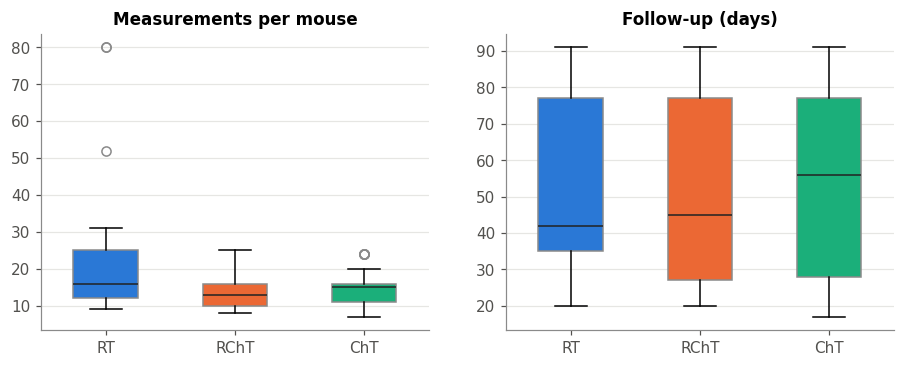

,mice,measurements,per_mouse,follow_up_days
role,,,,
RT,73,1444,16 [12–25],42 [35–77]
RChT,60,837,13 [10–16],45 [27–77]
ChT,53,768,15 [11–16],56 [28–77]


Mice with more than 40 measurements:


,role,n,first,last,follow_up_days,cell_line
item_id,,,,,,
380,1,80,2016-05-09,2016-08-08,91,OH-1 RGB
392,1,52,2016-05-09,2016-07-11,63,OH-1 RGB
423,1,80,2016-05-09,2016-08-08,91,OH-1 RGB


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, column, label in zip(axes, ["n", "follow_up_days"], ["Measurements per mouse", "Follow-up (days)"]):
    data = [per_mouse.loc[per_mouse["role"] == r, column] for r in COHORT_ROLES]
    box = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops={"color": INK}, flierprops={"markeredgecolor": MUTED})
    for patch, r in zip(box["boxes"], COHORT_ROLES):
        patch.set_facecolor(THERAPY_COLORS[r])
        patch.set_edgecolor(MUTED)
    ax.set_xticks(range(1, 4), [THERAPY_ABBR[r] for r in COHORT_ROLES])
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
plt.show()
display(per_mouse.groupby("role").agg(mice=("n", "size"), measurements=("n", "sum"), per_mouse=("n", median_iqr),
                                      follow_up_days=("follow_up_days", median_iqr)).rename(index=THERAPY_ABBR))
print("Mice with more than 40 measurements:")
display(per_mouse.loc[per_mouse["n"] > 40, ["role", "n", "first", "last", "follow_up_days", "cell_line"]])

Gaps between consecutive measurements, overall and by treatment phase. The phase of a gap is that of
its later measurement: *before treatment* (before the first treatment day), *treatment period*
(first to last treatment day) and *after treatment*.

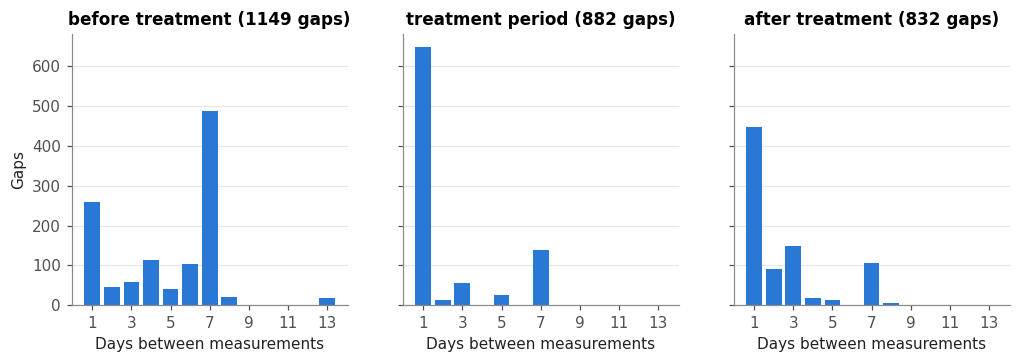

,gaps,median,mean,max
phase,,,,
before treatment,1149,6.0,4.899043,13.0
treatment period,882,1.0,2.205215,7.0
after treatment,832,1.0,2.409856,8.0


gap,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,10.0,13.0
% of all gaps,47.4,5.2,9.2,4.6,2.8,3.6,25.6,0.9,0.0,0.6


'47.4% / 25.6%'

In [35]:
gaps = series[["item_id", "timestamp", "target", "intervention"]].copy()
gaps["gap"] = gaps.groupby("item_id")["timestamp"].diff().dt.days
gaps["delta"] = gaps.groupby("item_id")["target"].diff()
gaps = gaps.join(per_mouse[["role", "first_treatment", "last_treatment", "baseline"]], on="item_id")
gaps["phase"] = np.select(
    [gaps["timestamp"] < gaps["first_treatment"], gaps["timestamp"] <= gaps["last_treatment"]],
    ["before treatment", "treatment period"], "after treatment")
phases = ["before treatment", "treatment period", "after treatment"]
g = gaps.dropna(subset=["gap"])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True, sharex=True)
for ax, phase in zip(axes, phases):
    counts = g.loc[g["phase"] == phase, "gap"].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=THERAPY_COLORS[1], width=0.8)
    ax.set_title(f"{phase} ({counts.sum()} gaps)")
    ax.set_xlabel("Days between measurements")
    ax.set_xticks([1, 3, 5, 7, 9, 11, 13])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Gaps")
plt.show()
display(g.groupby("phase")["gap"].agg(gaps="size", median="median", mean="mean", max="max").loc[phases])
gap_share = g["gap"].value_counts(normalize=True).sort_index().mul(100).round(1)
display(gap_share.rename("% of all gaps").to_frame().T)
fact("Gap between measurements: 1 day / 7 days (% of gaps)", f"{gap_share.get(1, 0)}% / {gap_share.get(7, 0)}%")

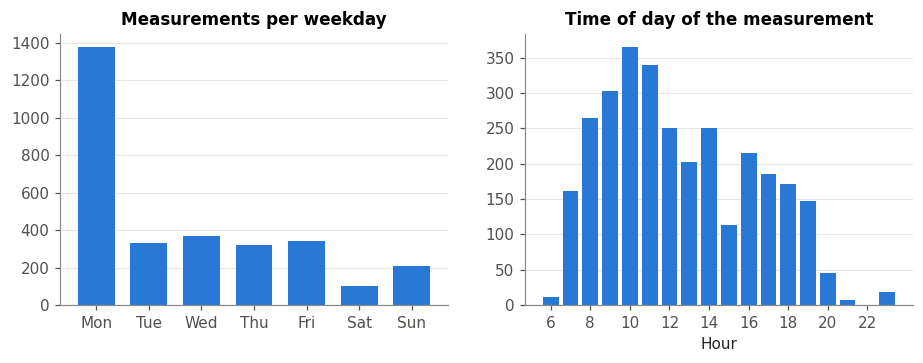

In [36]:
weekday = series["timestamp"].dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).fillna(0)
hour = pd.to_datetime(series["time"].astype(str), format="%H:%M:%S", errors="coerce").dt.hour
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(range(7), weekday.values, color=THERAPY_COLORS[1], width=0.7)
axes[0].set_xticks(range(7), [d[:3] for d in weekday.index])
axes[0].set_title("Measurements per weekday")
hours = hour.value_counts().sort_index()
axes[1].bar(hours.index, hours.values, color=THERAPY_COLORS[1], width=0.8)
axes[1].set_xticks(range(6, 24, 2))
axes[1].set_title("Time of day of the measurement")
axes[1].set_xlabel("Hour")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.show()

Before treatment the mice are weighed about once a week (median gap 6 days, most often 7 days,
typically on Mondays).
From the first treatment on they are weighed almost daily (median gap 1 day). The sampling density
therefore changes exactly where the weight starts to fall.

Calendar view of the cohort: one line per mouse from its first to its last measurement, small ticks
on treatment days. Mice that overlap in calendar time can serve as context for each other in the
trail-context model. Long gaps without any mouse are cut out of the time axis.

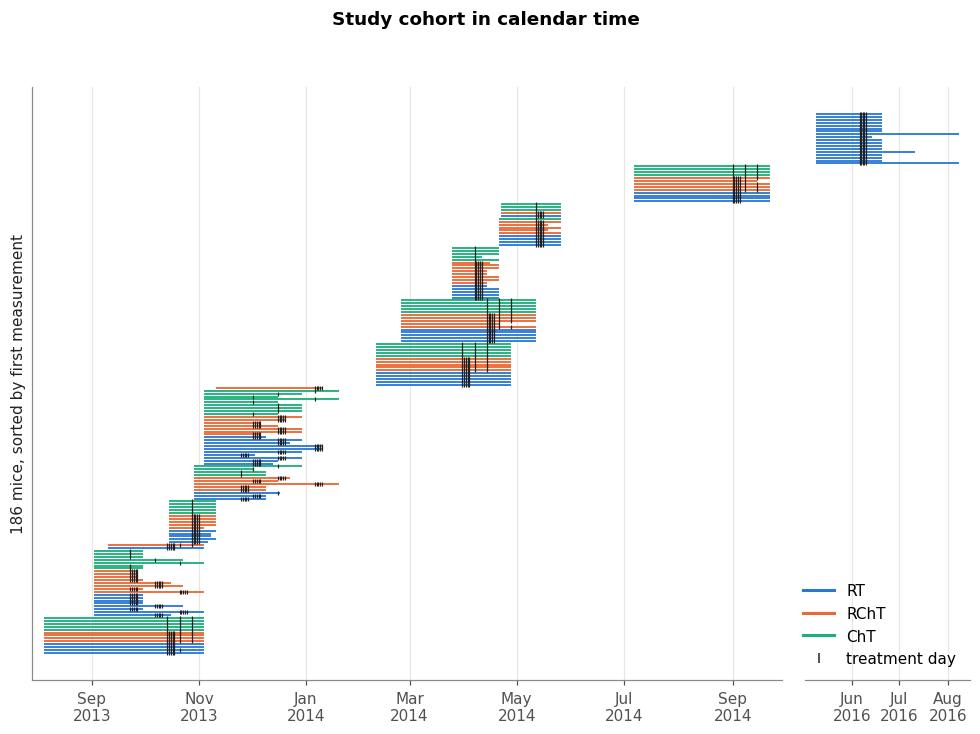

therapy,ChT,RChT,RT,Total
year of first measurement,,,,
2013,30,31,31,92
2014,23,29,24,76
2016,0,0,18,18
Total,53,60,73,186


,mice,measurements,per_mouse,cell_line
role,,,,
RT,18,671,31 [31–31],OH-1 RGB


In [37]:
order = per_mouse.sort_values(["first", "role"]).index
y_of = {m: i for i, m in enumerate(order)}
dates = np.sort(series["timestamp"].unique())
breaks = np.where(np.diff(dates) > np.timedelta64(120, "D"))[0]
segments = np.split(dates, breaks + 1)
widths = [max((s[-1] - s[0]) / np.timedelta64(1, "D"), 30) for s in segments]
fig, axes = plt.subplots(1, len(segments), figsize=(11, 7), sharey=True, gridspec_kw={"width_ratios": widths, "wspace": 0.05})
axes = np.atleast_1d(axes)
treat = series[series["intervention"] > 0]
for ax, seg in zip(axes, segments):
    for mouse, row in per_mouse.loc[order].iterrows():
        ax.plot([row["first"], row["last"]], [y_of[mouse]] * 2, color=THERAPY_COLORS[row["role"]], linewidth=1.2, solid_capstyle="butt")
    ax.scatter(treat["timestamp"], treat["item_id"].map(y_of), marker="|", s=10, color=INK, linewidth=0.8, zorder=3)
    ax.set_xlim(seg[0] - np.timedelta64(7, "D"), seg[-1] + np.timedelta64(7, "D"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2 if len(seg) > 1 and (seg[-1] - seg[0]) > np.timedelta64(200, "D") else 1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.grid(axis="y", visible=False)
for ax in axes[1:]:
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", left=False)
axes[0].set_yticks([])
axes[0].set_ylabel(f"{len(order)} mice, sorted by first measurement")
handles = [plt.Line2D([], [], color=THERAPY_COLORS[r], label=THERAPY_ABBR[r]) for r in COHORT_ROLES]
handles.append(plt.Line2D([], [], color=INK, marker="|", linestyle="", label="treatment day"))
axes[-1].legend(handles=handles, loc="lower right")
fig.suptitle("Study cohort in calendar time", fontweight="bold")
plt.show()
display(named_crosstab(per_mouse["first"].dt.year.rename("year of first measurement"),
                       per_mouse["role"].map(THERAPY_ABBR).rename("therapy")))
late = per_mouse[per_mouse["first"].dt.year >= 2016]
display(late.groupby("role").agg(mice=("n", "size"), measurements=("n", "sum"), per_mouse=("n", median_iqr),
                                 cell_line=("cell_line", "first")).rename(index=THERAPY_ABBR))

Most mice were measured between August 2013 and September 2014, in overlapping injection
batches. The 18 mice of the May 2016 OH-1 batch are all RT mice and were weighed daily. With up to
80 measurements each they hold the longest series of the cohort, and they hardly overlap in time
with any other mouse.

Size of the trail context. For every forecast origin of the rolling evaluation, the trail-context
model sees the other cohort mice with more than `MIN_CONTEXT` measurements up to the date of the last
own measurement (`context.pool_rows`). Below: how many mice and rows that pool holds.

186 mice -> 2677 forecast origins


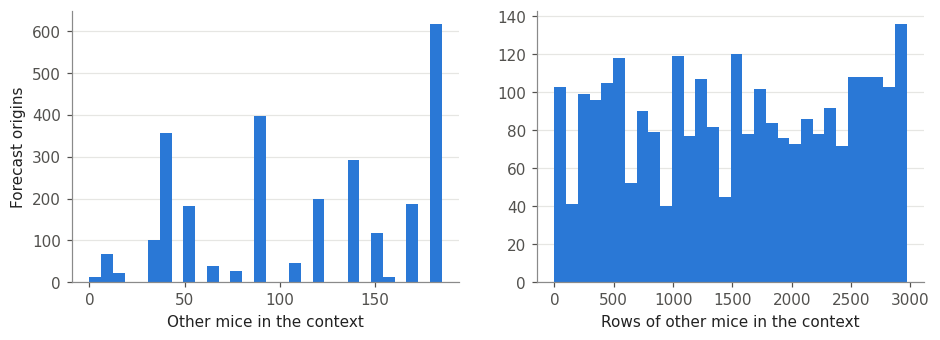

,count,mean,std,min,25%,50%,75%,max
pool_mice,2677.0,113.2,57.8,0.0,52.0,121.0,167.0,185.0
pool_rows,2677.0,1539.4,885.6,0.0,740.0,1552.0,2325.0,2968.0


Origins without any other mouse in the context: 13 of 2677


In [38]:
contexts, origins = rolling_origins(df, min_context=MIN_CONTEXT)
origins["cutoff"] = origins["item_id"].map(contexts.groupby("item_id")["timestamp"].max())
times_of = {m: np.sort(s["timestamp"].to_numpy()) for m, s in series.groupby("item_id")}
cutoffs = np.sort(origins["cutoff"].unique())
counts = pd.DataFrame({m: np.searchsorted(t, cutoffs, side="right") for m, t in times_of.items()}, index=cutoffs)
eligible = counts.where(counts > MIN_CONTEXT, 0)


def pool_size(row):
    own = eligible.loc[row["cutoff"], row["mouse_id"]]
    total = eligible.loc[row["cutoff"]]
    return pd.Series({"pool_mice": int((total > 0).sum() - (own > 0)), "pool_rows": int(total.sum() - own)})


origins = origins.join(origins.apply(pool_size, axis=1))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(origins["pool_mice"], bins=30, color=THERAPY_COLORS[1])
axes[0].set_xlabel("Other mice in the context")
axes[1].hist(origins["pool_rows"], bins=30, color=THERAPY_COLORS[1])
axes[1].set_xlabel("Rows of other mice in the context")
axes[0].set_ylabel("Forecast origins")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.show()
display(origins[["pool_mice", "pool_rows"]].describe().T.round(1))
print(f"Origins without any other mouse in the context: {int((origins['pool_mice'] == 0).sum())} of {len(origins)}")

The pool only contains mice measured on or before the forecast date. It therefore grows with
calendar time, from almost empty for the first batch to all other mice for the 2016 batch, which
sees the complete earlier lives of the 2013–2014 mice.

## C4. Weight trajectories
All series per therapy group, aligned at the first treatment day (day 0). Thin grey lines are
single mice. The coloured line is the median over mice in 3-day bins centred on day 0, ±3, ±6, ...
Each mouse counts once per bin (its mean), so the daily-weighed mice do not dominate; bins with fewer
than 15 mice are not drawn.

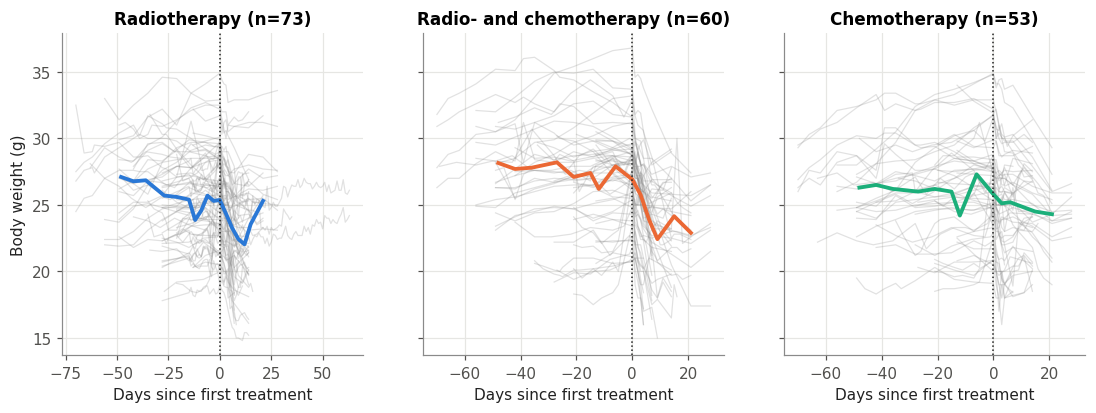

In [39]:
traj = series.join(per_mouse[["first_treatment", "baseline", "last"]], on="item_id")
traj["day_rel_treatment"] = (traj["timestamp"] - traj["first_treatment"]).dt.days
traj["day_rel_first"] = (traj["timestamp"] - traj.groupby("item_id")["timestamp"].transform("min")).dt.days
traj["days_before_last"] = (traj["last"] - traj["timestamp"]).dt.days
traj["rel_weight"] = 100 * traj["target"] / traj["baseline"]


def median_line(data, x, y, width=3, min_n=15):
    """Median and IQR over mice in bins of ``width`` days centred on 0; each mouse counts once per bin."""
    per_mouse_bin = data.assign(bin=np.round(data[x] / width) * width).groupby(["bin", "item_id"])[y].mean()
    q = per_mouse_bin.groupby("bin").agg(n="size", q1=lambda v: v.quantile(0.25), med="median", q3=lambda v: v.quantile(0.75))
    return q[q["n"] >= min_n]


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, role in zip(axes, COHORT_ROLES):
    sub = traj[traj["role"] == role]
    for _, s in sub.groupby("item_id"):
        ax.plot(s["day_rel_treatment"], s["target"], color=MUTED, alpha=0.25, linewidth=0.8)
    q = median_line(sub, "day_rel_treatment", "target")
    ax.plot(q.index, q["med"], color=THERAPY_COLORS[role], linewidth=2.5)
    ax.axvline(0, color=INK, linestyle=":", linewidth=1)
    ax.set_title(f"{THERAPY_TYPES[role]} (n={sub['item_id'].nunique()})")
    ax.set_xlabel("Days since first treatment")
axes[0].set_ylabel("Body weight (g)")
plt.show()

Relative weight (% of the baseline weight) of the three groups on one axis, aligned at the first
treatment (left) and at the last measurement (right). Median with interquartile range.

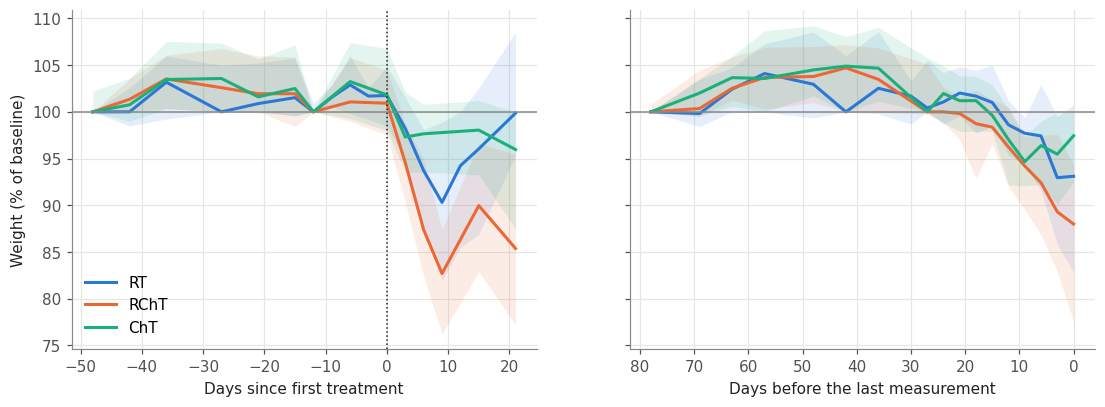

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, x, label in zip(axes, ["day_rel_treatment", "days_before_last"], ["Days since first treatment", "Days before the last measurement"]):
    for role in COHORT_ROLES:
        q = median_line(traj[traj["role"] == role], x, "rel_weight")
        ax.fill_between(q.index, q["q1"], q["q3"], color=THERAPY_COLORS[role], alpha=0.12, linewidth=0)
        ax.plot(q.index, q["med"], color=THERAPY_COLORS[role], label=THERAPY_ABBR[role])
    ax.axhline(100, color=MUTED, linewidth=1)
    ax.set_xlabel(label)
axes[1].invert_xaxis()
axes[0].axvline(0, color=INK, linestyle=":", linewidth=1)
axes[0].set_ylabel("Weight (% of baseline)")
axes[0].legend()
plt.show()

Before treatment the weights are stable or rise slightly. After the first treatment the weight
falls in all groups: most strongly and for longest after radiochemotherapy, least after chemotherapy
alone. Only about 20 mice per group are followed for more than three weeks after the first
treatment, so the right end of the left panel rests on few mice. Aligned at the end (right panel),
the weight falls over the last two weeks of a series, which matters for the `days_before_death`
analysis of the results.

Weight change between consecutive measurements (the quantity a one-step forecast has to get right),
by phase and by the length of the gap.

,changes,mean,sd,median,q05,q95
phase,,,,,,
before treatment,1149,0.11,0.74,0.1,-1.00,1.20
treatment period,882,-0.40,1.14,-0.3,-1.99,0.90
after treatment,832,-0.26,1.13,-0.1,-2.20,1.14


,changes,mean_abs,sd
gap (days),,,
1,1356,0.55,0.82
2–3,413,0.94,1.39
4–6,317,0.77,1.31
7,732,0.65,0.89
>7,45,0.72,0.83


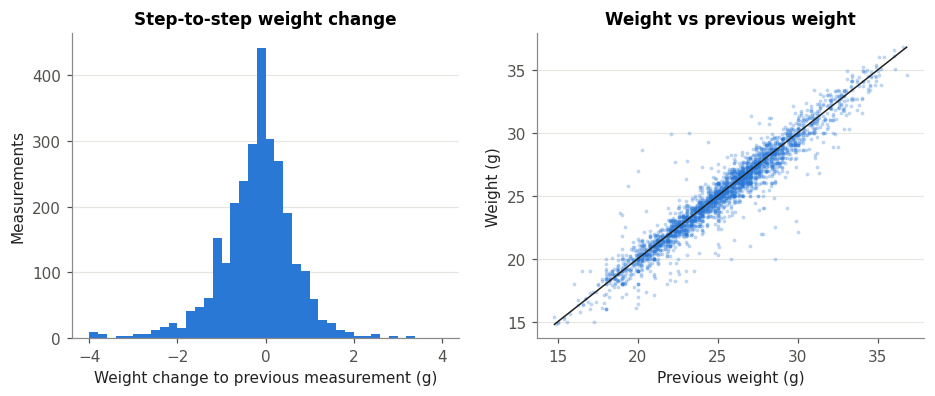

Correlation weight vs previous weight: 0.962
Correlation weight change vs previous weight change: -0.122
SD of the mean weight between mice: 3.35 g, SD of the weight within a mouse: 1.66 g


In [41]:
display(g.groupby("phase")["delta"].agg(changes="size", mean="mean", sd="std", median="median",
                                       q05=lambda x: x.quantile(0.05), q95=lambda x: x.quantile(0.95)).loc[phases].round(2))
display(g.assign(gap_group=pd.cut(g["gap"], [0, 1, 3, 6, 7, 30], labels=["1", "2–3", "4–6", "7", ">7"]))
        .groupby("gap_group", observed=True)["delta"].agg(changes="size", mean_abs=lambda x: x.abs().mean(), sd="std").round(2)
        .rename_axis("gap (days)"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(g["delta"], bins=np.arange(-4, 4.01, 0.2), color=THERAPY_COLORS[1])
axes[0].set_xlabel("Weight change to previous measurement (g)")
axes[0].set_ylabel("Measurements")
axes[0].set_title("Step-to-step weight change")
lagged = g.assign(prev=g["target"] - g["delta"])
axes[1].scatter(lagged["prev"], lagged["target"], s=6, alpha=0.3, color=THERAPY_COLORS[1], linewidth=0)
lims = [lagged[["prev", "target"]].min().min(), lagged[["prev", "target"]].max().max()]
axes[1].plot(lims, lims, color=INK, linewidth=1)
axes[1].set_xlabel("Previous weight (g)")
axes[1].set_ylabel("Weight (g)")
axes[1].set_title("Weight vs previous weight")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.show()

delta_ac = g.assign(prev_delta=g.groupby("item_id")["delta"].shift()).dropna(subset=["prev_delta"])
mouse_mean = series.groupby("item_id")["target"].mean()
within_sd = (series["target"] - series["item_id"].map(mouse_mean)).std()
print(f"Correlation weight vs previous weight: {np.corrcoef(lagged['prev'], lagged['target'])[0, 1]:.3f}")
print(f"Correlation weight change vs previous weight change: {np.corrcoef(delta_ac['prev_delta'], delta_ac['delta'])[0, 1]:.3f}")
print(f"SD of the mean weight between mice: {mouse_mean.std():.2f} g, SD of the weight within a mouse: {within_sd:.2f} g")

Consecutive weights are highly correlated, so the last weight is already a strong forecast
(see C7). Consecutive changes are slightly negatively correlated: a jump tends to be partly undone at
the next visit, which is typical of measurement noise (food, faeces, time of day). Mice differ more
from each other than a mouse varies over its life, so the level of a mouse is easy and its change is
the hard part. The changes are largest, and mostly negative, during the treatment period.

Baseline weight, lowest weight and weight at the last measurement by sex and cell line.

In [42]:
by = per_mouse.assign(cell_line=per_mouse["cell_line"].str.replace(" RGB", ""))
summary = lambda d: pd.Series({"mice": len(d), "baseline_g": median_iqr(d["baseline"], 1),
                               "lowest_pct_of_baseline": median_iqr(d["nadir_pct"], 1),
                               "last_weight_g": median_iqr(d["last_weight"], 1)})
display(by.groupby("sex").apply(summary, include_groups=False))
display(by.groupby("cell_line").apply(summary, include_groups=False))
display(by.groupby(["cell_line", "sex"]).apply(summary, include_groups=False))

,mice,baseline_g,lowest_pct_of_baseline,last_weight_g
sex,,,,
female,64,22.2 [20.6–23.6],86.1 [80.6–90.2],19.8 [18.2–21.4]
male,122,27.1 [25.6–29.0],91.8 [83.0–96.7],25.2 [23.1–26.8]


,mice,baseline_g,lowest_pct_of_baseline,last_weight_g
cell_line,,,,
H69,47,25.7 [22.4–27.6],87.5 [83.4–92.9],23.7 [20.2–25.6]
LNCaP,58,26.4 [24.7–28.2],94.0 [82.8–98.4],24.6 [23.3–26.3]
OH-1,81,24.6 [22.2–27.4],86.8 [79.9–94.2],21.5 [19.6–25.4]


mice        baseline_g lowest_pct_of_baseline     last_weight_g
cell_line sex                                                                    
H69       female    21  22.2 [20.6–23.8]       85.1 [82.1–89.6]  20.1 [18.4–21.9]
          male      26  27.6 [26.9–28.4]       88.0 [85.3–93.5]  25.5 [24.3–26.6]
LNCaP     male      58  26.4 [24.7–28.2]       94.0 [82.8–98.4]  24.6 [23.3–26.3]
OH-1      female    43  22.2 [20.6–23.5]       86.1 [80.3–90.4]  19.7 [18.2–21.1]
          male      38  27.5 [26.3–29.5]       89.5 [79.1–96.6]  25.9 [22.4–27.1]

Female mice are about 5 g lighter than male mice and lose relatively more weight. All LNCaP
(prostate) mice are male.

Three example mice, the one with the median number of measurements in each group, with the
treatment days marked.

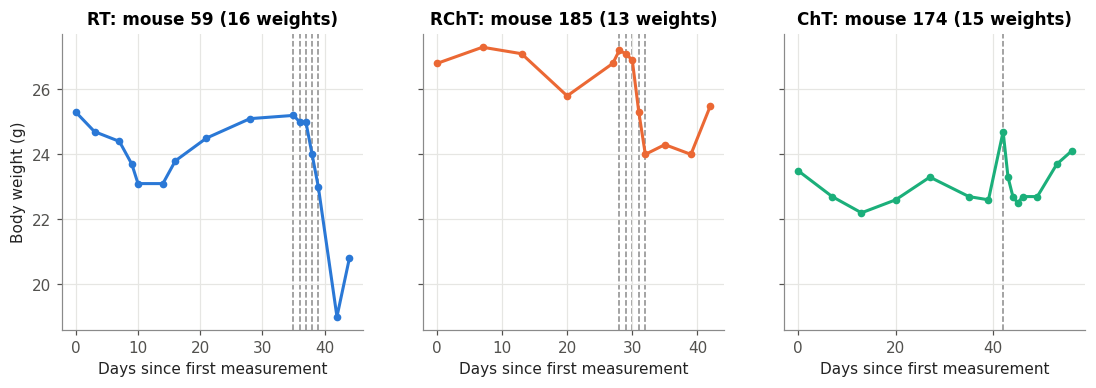

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, role in zip(axes, COHORT_ROLES):
    pm = per_mouse[per_mouse["role"] == role]
    mouse = (pm["n"] - pm["n"].median()).abs().sort_values(kind="stable").index[0]
    s = traj[traj["item_id"] == mouse]
    ax.plot(s["day_rel_first"], s["target"], color=THERAPY_COLORS[role], marker="o", markersize=4)
    for day in s.loc[s["intervention"] > 0, "day_rel_first"]:
        ax.axvline(day, color=MUTED, linestyle="--", linewidth=1, zorder=0)
    ax.set_title(f"{THERAPY_ABBR[role]}: mouse {mouse} ({len(s)} weights)")
    ax.set_xlabel("Days since first measurement")
axes[0].set_ylabel("Body weight (g)")
plt.show()

## C5. Treatments within the series
After preprocessing each treatment day is one row with `intervention = 1` (radio and chemo counted
separately). The position of the first treatment tells how much own history a mouse has before
the treatment starts.

In [44]:
treat_table = per_mouse.groupby("role").agg(
    mice=("n", "size"),
    rows=("n", "sum"),
    rows_with_intervention=("intervention_days", "sum"),
    RT_days_per_mouse=("rt_days", median_iqr),
    ChT_days_per_mouse=("cht_days", median_iqr),
    measurements_before_first_treatment=("first_treatment_index", median_iqr),
    days_first_to_last_treatment=("last_treatment", lambda x: median_iqr((x - per_mouse.loc[x.index, "first_treatment"]).dt.days)),
).rename(index=THERAPY_ABBR)
treat_table["share_of_rows_with_intervention"] = (100 * treat_table["rows_with_intervention"] / treat_table["rows"]).round(1).astype(str) + "%"
display(treat_table)
fact("Rows with a treatment (intervention = 1)", n_pct(int(df["intervention"].sum()), len(df)))

origins = origins.join(per_mouse[["first_treatment_index", "role"]], on="mouse_id")
origins["context_has_treatment"] = origins["step"] > origins["first_treatment_index"]
origins["target_is_treatment_day"] = origins["intervention"] > 0
display(origins.groupby("role")[["context_has_treatment", "target_is_treatment_day"]].mean().mul(100).round(1)
        .rename(index=THERAPY_ABBR).rename(columns=lambda c: f"% of forecast origins: {c.replace('_', ' ')}"))

,mice,rows,rows_with_intervention,RT_days_per_mouse,ChT_days_per_mouse,measurements_before_first_treatment,days_first_to_last_treatment,share_of_rows_with_intervention
role,,,,,,,,
RT,73,1444,362,5 [5–5],0 [0–0],7 [5–14],4 [4–4],25.1%
RChT,60,837,338,5 [5–5],1 [1–3],6 [3–8],4 [4–14],40.4%
ChT,53,768,91,0 [0–0],1 [1–3],7 [3–8],0 [0–14],11.8%


,% of forecast origins: context has treatment,% of forecast origins: target is treatment day
role,,
RT,56.9,27.9
RChT,57.9,47.1
ChT,56.6,13.7


A quarter of all rows are treatment days. Each mouse has a median of 6–7 weights before its first
treatment. Just over half of the forecast origins already have a treatment in their own context,
and in the RChT group almost half of the forecast targets are treatment days themselves.

## C6. Weight loss and endpoints
Lowest weight relative to the baseline, how many mice crossed common weight-loss limits, how this
relates to the cause of death, and how close the last measurement is to death.

,mice,lowest_weight_pct_of_baseline,loss_at_least_10pct,loss_at_least_15pct,loss_at_least_20pct
role,,,,,
RT,73,89.7 [80.3–95.6],38 (52%),26 (36%),18 (25%)
RChT,60,84.2 [77.2–89.7],46 (77%),31 (52%),20 (33%)
ChT,53,92.8 [85.7–97.0],22 (42%),11 (21%),3 (6%)


death_cause,Experiment ended as planned,Killed: poor general condition,Killed: tumour ulceration,Spontaneous death,Unknown,Unknown: disposed of by animal care,Total
loss_group,,,,,,,
< 10%,76,1,0,1,2,0,80
10–15%,29,1,0,2,4,2,38
15–20%,22,1,1,3,0,0,27
≥ 20%,26,8,0,2,2,3,41
Total,153,11,1,8,8,5,186


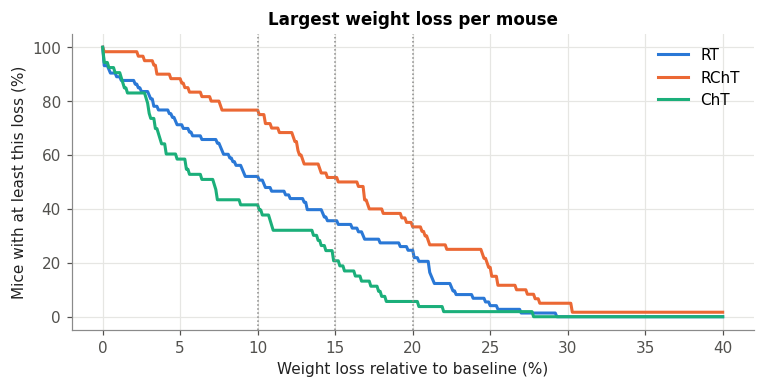

In [45]:
loss = per_mouse.assign(loss_pct=100 - per_mouse["nadir_pct"])
loss_table = loss.groupby("role").agg(
    mice=("n", "size"),
    lowest_weight_pct_of_baseline=("nadir_pct", lambda x: median_iqr(x, 1)),
    **{f"loss_at_least_{t}pct": ("loss_pct", lambda x, t=t: n_pct(int((x >= t).sum()), len(x))) for t in (10, 15, 20)},
).rename(index=THERAPY_ABBR)
display(loss_table)
loss["loss_group"] = pd.cut(loss["loss_pct"], [-100, 10, 15, 20, 100], labels=["< 10%", "10–15%", "15–20%", "≥ 20%"], right=False)
display(named_crosstab(loss["loss_group"], loss["death_cause"]))

fig, ax = plt.subplots(figsize=(8, 3.5))
thresholds = np.linspace(0, 40, 401)
for role in COHORT_ROLES:
    values = loss.loc[loss["role"] == role, "loss_pct"].to_numpy()
    share = [(values >= t).mean() * 100 for t in thresholds]
    ax.plot(thresholds, share, color=THERAPY_COLORS[role], label=THERAPY_ABBR[role])
for t in (10, 15, 20):
    ax.axvline(t, color=MUTED, linestyle=":", linewidth=1)
ax.set_xlabel("Weight loss relative to baseline (%)")
ax.set_ylabel("Mice with at least this loss (%)")
ax.set_title("Largest weight loss per mouse")
ax.legend()
plt.show()

In [46]:
display(per_mouse["last_to_death"].value_counts().sort_index().rename("mice").rename_axis("days from last measurement to death").to_frame().T)
fact("Days from last measurement to death", median_iqr(per_mouse["last_to_death"]))

days from last measurement to death,0,1,2,3,4,5,6,7
mice,42,125,1,9,6,1,1,1


'1 [1–1]'

The last measurement is almost always one day before death, or on the day itself. The
`days_before_death` axis in the results (`rolling.py`) counts from the last measurement, which is
therefore a close stand-in for the day of death.

About a fifth of the cohort lost at least 20% of its baseline weight at some point, almost all of
them in the irradiated groups (RT and RChT). Even so, most of these mice still ended the experiment
as planned: weight loss alone rarely ended a series early.

## C7. Evaluation footprint
The rolling one-step-ahead evaluation predicts every measurement from the `MIN_CONTEXT + 1`-th on
from all earlier weights of the same mouse. Number of forecast origins per group and how much own
context they have.

,mice,forecast_origins,context_length,gap_to_target_days
role,,,,
RT,73,1298,11 [6–20],1 [1–3]
RChT,60,717,7 [4–11],3 [1–7]
ChT,53,662,8 [5–12],3 [1–7]
Overall,186,2677,9 [5–14],1 [1–7]


The 18 RT mice of the 2016 batch account for 635 of the 1298 RT forecast origins (49%) and 24% of all origins.

Forecast origins = rows - 2 × mice = 3049 - 2 × 186 = 2677
Cached forecasts in /data/PFN/Mouse/rolling/tabpfn_trail3.parquet: 2677 rows, same origins as here: True


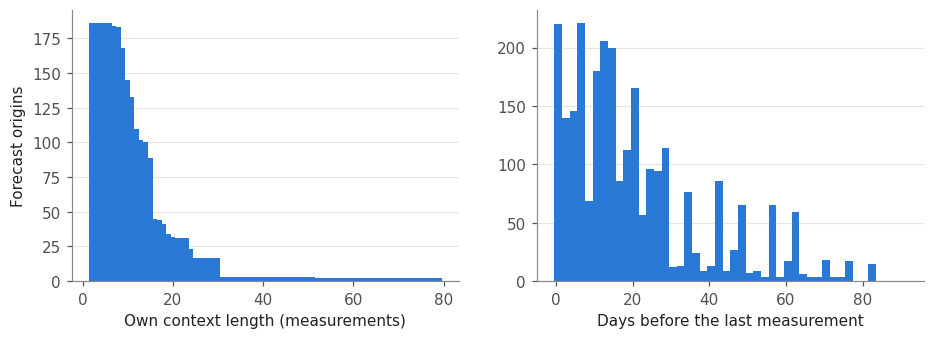

In [47]:
origins["gap"] = (origins["timestamp"] - origins["cutoff"]).dt.days
origins["days_before_last"] = (origins["mouse_id"].map(per_mouse["last"]) - origins["timestamp"]).dt.days
footprint = origins.groupby("role").agg(
    mice=("mouse_id", "nunique"),
    forecast_origins=("item_id", "size"),
    context_length=("step", median_iqr),
    gap_to_target_days=("gap", median_iqr),
).rename(index=THERAPY_ABBR)
footprint.loc["Overall"] = [origins["mouse_id"].nunique(), len(origins), median_iqr(origins["step"]), median_iqr(origins["gap"])]
display(footprint)
late_origins = origins["mouse_id"].isin(late.index)
display(Markdown(
    f"The {late.shape[0]} RT mice of the 2016 batch account for {late_origins.sum()} of the "
    f"{(origins['role'] == 1).sum()} RT forecast origins ({100 * late_origins.sum() / (origins['role'] == 1).sum():.0f}%) "
    f"and {100 * late_origins.mean():.0f}% of all origins."
))
fact("RT forecast origins from the daily-weighed 2016 batch (18 mice)",
     n_pct(int(late_origins.sum()), int((origins["role"] == 1).sum())))
fact("Forecast origins in the rolling evaluation", len(origins))
print(f"Forecast origins = rows - {MIN_CONTEXT} × mice = {len(df)} - {MIN_CONTEXT} × {df['item_id'].nunique()} = "
      f"{len(df) - MIN_CONTEXT * df['item_id'].nunique()}")

if os.path.exists(ROLLING_CACHE):
    cached = pd.read_parquet(ROLLING_CACHE)
    same = set(cached["item_id"]) == set(origins["item_id"])
    print(f"Cached forecasts in {ROLLING_CACHE}: {len(cached)} rows, same origins as here: {same}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(origins["step"], bins=np.arange(1.5, origins["step"].max() + 1.5), color=THERAPY_COLORS[1])
axes[0].set_xlabel("Own context length (measurements)")
axes[0].set_ylabel("Forecast origins")
axes[1].hist(origins["days_before_last"], bins=np.arange(-0.5, 92.5, 2), color=THERAPY_COLORS[1])
axes[1].set_xlabel("Days before the last measurement")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.show()

For scale: the error of the naive forecast "next weight = last weight" on exactly these origins,
computed with the metric functions of the results notebook (`rolling_metrics`: mean over origins
per group, *Overall* is the mean of the three groups). This is a reference point for reading the
model errors, not one of the models of the paper.

In [48]:
last_value = {
    "Last value (naive reference)": lambda c, t: c.sort_values(["item_id", "timestamp"]).groupby("item_id", as_index=False)["target"]
    .last().rename(columns={"target": "prediction"})
}
naive = rolling_metrics(rolling_predictions(df, last_value, min_context=MIN_CONTEXT))
fact("Naive last-value forecast: MAE overall (g)", round(float(naive.xs("Overall", level="role")["MAE"].iloc[0]), 3))
naive.round(4)

186 mice -> 2677 forecast origins


n     MAE    MAPE
model                        role                                         
Last value (naive reference) Chemotherapy              662  0.7008  0.0283
                             Overall                  2677  0.6953  0.0284
                             Radio- and chemotherapy   717  0.8435  0.0344
                             Radiotherapy             1298  0.5415  0.0226

The metrics weight every forecast origin equally within a group. In the RT group the 18 daily-weighed
mice of 2016 contribute a large share of the origins, with short gaps and therefore small
changes, which is one reason why the naive error is lowest for RT.

## C8. Data quality in the cohort
What the preprocessing changed on the way from the raw visits to the series.

In [49]:
visits_c = events_dated[(events_dated["id"].isin(keep)) & (events_dated["event"] == "visit")]
same_day_visits = visits_c.groupby(["id", "date"]).size()
print(f"Mouse-days with more than one visit (weights averaged): {int((same_day_visits > 1).sum())}")

treat_ev = kept_events[kept_events["event"].isin(michael.TREATMENTS)].reset_index()
vis_ev = kept_events[kept_events["event"] == "visit"].reset_index()
pairs = treat_ev[["index", "id", "days_since", "event"]].merge(vis_ev[["index", "id", "days_since"]], on="id", suffixes=("", "_visit"))
pairs["distance"] = (pairs["days_since"] - pairs["days_since_visit"]).abs()
nearest = pairs.sort_values(["index", "distance", "index_visit"]).drop_duplicates("index")
display(pd.crosstab(nearest["event"], nearest["distance"]).rename_axis(index="treatment", columns="days to the nearest visit"))
print("A treatment takes over the weight of its nearest visit; that visit is removed, so its weight moves to the treatment date.")
print(f"Visits absorbed this way: {nearest['index_visit'].nunique()}")

display(Markdown("**Mice excluded for implausible weights** (raw visits):"))
for mouse in excluded.index:
    display(visits[visits["id"] == mouse][["id", "date", "weight", "score"]].tail(4))

Mouse-days with more than one visit (weights averaged): 10


days to the nearest visit,0,1
treatment,,
chemo,188,2
radio,660,1


A treatment takes over the weight of its nearest visit; that visit is removed, so its weight moves to the treatment date.
Visits absorbed this way: 790


**Mice excluded for implausible weights** (raw visits):

,id,date,weight,score
1673,82,2013-10-23,17.0,5
1702,82,2013-10-24,17.0,5
1708,82,2013-10-25,15.0,15
1741,82,2013-10-28,0.0,0


,id,date,weight,score
4843,313,2014-05-15,22.0,5
4867,313,2014-05-16,22.0,5
4914,313,2014-05-19,21.5,5
4959,313,2014-05-26,222.2,5


Two loaders exist. The results use `michael.load_dataset` (the preprocessing behind the Eagle-eye
baseline, MIE 2025). `preprocessing.load_dataset` keeps all visits and attaches treatments to the
nearest visit instead of moving the weight. Same configuration, for comparison:

In [50]:
alt = preprocessing.load_dataset(DATAPATH, PreprocessingConfig(**{**config.__dict__, "prediction_length": 1}))
pd.DataFrame({
    "michael.load_dataset (used)": [df["item_id"].nunique(), len(df), int(df["intervention"].sum()), df["timestamp"].min().date()],
    "preprocessing.load_dataset": [alt["item_id"].nunique(), len(alt), int(alt["intervention"].sum()), alt["timestamp"].min().date()],
}, index=["mice", "rows", "rows with intervention", "first date"])

Animals: 188 -> 186 after filtering -> 186 sampled


,michael.load_dataset (used),preprocessing.load_dataset
mice,186,186
rows,3049,3084
rows with intervention,791,790
first date,2013-08-05,2013-06-17


# Part D: facts for the paper
The key numbers collected above, in one place.

In [51]:
FACTS.update({
    "Study cohort: RT / RChT / ChT mice": " / ".join(str(int((per_mouse["role"] == r).sum())) for r in COHORT_ROLES),
    "Study cohort: male": n_pct(int((per_mouse["sex"] == "male").sum()), len(per_mouse)),
    "Study cohort: cell lines OH-1 / H69 / LNCaP": " / ".join(str(int((per_mouse["cell_line"] == c).sum())) for c in CELL_COLORS),
    "Study cohort: age at tumour injection (weeks)": median_iqr(per_mouse["age_injection_wk"], 1),
    "Study cohort: baseline weight (g)": median_iqr(per_mouse["baseline"], 1),
    "Study cohort: measurements per mouse": f"{median_iqr(per_mouse['n'])}, range {per_mouse['n'].min()}–{per_mouse['n'].max()}",
    "Study cohort: follow-up (days)": median_iqr(per_mouse["follow_up_days"]),
    "Study cohort: days from injection to first treatment": median_iqr(per_mouse["injection_to_treatment"]),
    "Study cohort: days from injection to death": median_iqr(per_mouse["injection_to_death"]),
    "Study cohort: killed at the planned end": n_pct(int((per_mouse["death_cause"] == DEATH_CAUSES[2]).sum()), len(per_mouse)),
    "Study cohort: weight loss ≥ 20% of baseline": n_pct(int((loss["loss_pct"] >= 20).sum()), len(loss)),
    "Study cohort: calendar period": f"{series['timestamp'].min():%Y-%m-%d} to {series['timestamp'].max():%Y-%m-%d}",
})
pd.Series(FACTS, name="value").to_frame()

,value
Tables in the database,25
Animals in the database,843
Visits in the database,22142
Trails (experiment series),15
Approved projects,12
Mice in trail 3,376
Trail 3: mice killed at the planned end of the experiment,296 (79%)
Study cohort: mice,186
Study cohort: daily weight measurements (rows),3049
Gap between measurements: 1 day / 7 days (% of gaps),47.4% / 25.6%
